# 🎃 AML Challenge 2026/27 — Semantic Correspondence
### Notebook self-contained: capire il problema, misurarlo bene, confrontare approcci

**Compito.** Dati *immagine sorgente*, *immagine target* e un punto $(x,y)$ sulla sorgente, restituire **un solo punto** sul target che corrisponde alla stessa parte semantica (es. naso → naso). Alcune query hanno **più target accettati** (es. due ruote): basta essere vicini a uno qualsiasi.

**Metrica (leaderboard).** PCK@0.10: la predizione è corretta se
$$\min_{a\in A(q)}\|\hat y(q)-a\|_2 \;\le\; 0.10\cdot L(q)$$
dove $L$ = lato più lungo del bounding box dell'oggetto target (colonna `scale` in `train.csv`; **nel test non è fornita**). Score = frazione di query corrette.

**Come è organizzato il notebook**

| § | contenuto |
|---|---|
| 1 | Setup e configurazione (tutto ciò che si può cambiare è qui) |
| 2 | Dati e analisi esplorativa (grafici) |
| 3 | Metrica, baseline banali, split senza leakage, intervalli di confidenza |
| 4 | Estrattore di feature DINOv2/DINOv3 (con cache) |
| 5 | Matching: mappa di similarità, decoding, TTA, ensemble, ri-ranking geometrico |
| 6 | Esperimenti A–J (ognuno con grafici) |
| 7 | Adapter addestrato sulle feature congelate |
| 8 | Confronto finale, analisi errori |
| 9 | Predizione sul test e file di submission |

> **Nota sui paper.** Qian et al. (CVPR 2025) osservano che le feature 2D (DINOv2, Stable Diffusion) *non sono invarianti al punto di vista*; propongono di fare ragionamento geometrico: fine-tuning di DUSt3R su dati sintetici cross-istanza per ricostruire i due oggetti in uno spazio 3D allineato, matching KNN geometrico + matching semantico sparso sui candidati. Qui **non** riproduciamo DUSt3R (non è nel perimetro di un notebook leggero), ma ne prendiamo l'idea: usare **vincoli geometrici** per disambiguare i candidati (§5.4, esperimento I). DINOv2/DINOv3 sono il backbone di feature dense self-supervised consigliato come punto di partenza.

## 1. Setup e configurazione

In [1]:
# !pip -q install -U torch transformers huggingface_hub pillow tqdm pandas matplotlib scipy
import os, json, math, hashlib, random, time, warnings
from collections import OrderedDict, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy import ndimage as ndi
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

# ============================ CONFIG ============================
DATA_DIR  = os.environ.get("AML_DATA", "aml-challenge-2026-27")   # cartella estratta da participant_data.zip
WORK_DIR  = os.environ.get("AML_WORK", "./work")               # cache feature, predizioni, submission
DRY_RUN   = os.environ.get("AML_DRY_RUN", "0") == "1"          # True = backend finto (smoke test senza modelli/GPU)

DINO_WEIGHTS = "weights/dinov3-vitb16-pretrain-lvd1689m.pth"
MODEL_MAIN, MODEL_FALLBACK = "local-dinov3-vitb16", "local-dinov3-vitb16"
EXTRA_MODELS = []                            # niente altri backbone, per ora
IMG_SIZE = 448
SEED      = 0
EVAL_MAX_PAIRS = None    # es. 120 per esperimenti rapidi; None = tutte le coppie
VAL_FRAC  = 0.25         # frazione di componenti connesse (immagini condivise) tenuta per validazione
PCK_THRS  = (0.05, 0.10, 0.20)
# ================================================================
os.makedirs(WORK_DIR, exist_ok=True); os.makedirs(f"{WORK_DIR}/feat_cache", exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
try:
    import torch; DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    torch = None; DEVICE = "cpu"
print("device:", DEVICE, "| DRY_RUN:", DRY_RUN, "| data:", os.path.abspath(DATA_DIR))

device: cpu | DRY_RUN: False | data: /home/lorenzo/Documenti/GitHub/Computer-Science-Sapienza/Advanced Machine Learning/Challenge/aml-challenge-2026-27


## 2. Dati e analisi esplorativa
Ogni riga di `train.csv` è una **query** (un punto sorgente). Più query condividono la stessa coppia, e la stessa immagine compare in più coppie → lo split train/validazione deve essere fatto per **componenti connesse di immagini**, altrimenti c'è leakage.
`*_pairs.json` contiene **tutti** i punti sorgente della coppia (anche quelli senza query): nel test sono un contesto geometrico utilizzabile (esperimento I).

In [2]:
def load_split(name):
    df = pd.read_csv(f"{DATA_DIR}/{name}.csv")
    pj = json.load(open(f"{DATA_DIR}/{name}_pairs.json"))["pairs"]
    pairs = {p["pair_id"]: p for p in pj}
    df["sw"] = df.pair_id.map(lambda p: pairs[p]["source_size"][0]); df["sh"] = df.pair_id.map(lambda p: pairs[p]["source_size"][1])
    df["tw"] = df.pair_id.map(lambda p: pairs[p]["target_size"][0]); df["th"] = df.pair_id.map(lambda p: pairs[p]["target_size"][1])
    df["n_src_pts"] = df.pair_id.map(lambda p: len(pairs[p]["source_xy"]))
    if "target_points" in df:
        df["targets"] = df.target_points.map(json.loads); df["n_targets"] = df.targets.map(len)
        df["rel_scale"] = df.scale / df[["tw", "th"]].max(axis=1)           # oggetto / immagine
    return df.reset_index(drop=True), pairs

tr, PAIRS_TR = load_split("train"); te, PAIRS_TE = load_split("test")
for d, ps in ((tr, PAIRS_TR), (te, PAIRS_TE)):   # controlli di coerenza descritti nel README
    assert all(np.allclose(ps[r.pair_id]["source_xy"][r.query_index], [r.source_x, r.source_y]) for r in d.itertuples())
print(f"train: {len(tr)} query, {tr.pair_id.nunique()} coppie, {len(set(tr.source_image)|set(tr.target_image))} immagini")
print(f"test : {len(te)} query, {te.pair_id.nunique()} coppie")
display(tr.drop(columns=["target_points", "targets"]).head(3))
# i file immagine esistono?
missing = [p for p in set(tr.source_image) | set(tr.target_image) | set(te.source_image) | set(te.target_image) if not os.path.exists(f"{DATA_DIR}/{p}")]
print("immagini mancanti:", len(missing), "(se >0 e non è DRY_RUN controlla DATA_DIR)")

train: 2495 query, 392 coppie, 517 immagini
test : 577 query, 98 coppie


,id,pair_id,source_image,target_image,query_index,source_x,source_y,scale,sw,sh,tw,th,n_src_pts,n_targets,rel_scale
0,train_q_02450,train_pair_0385,images/train/img_0061.jpeg,images/train/img_0439.jpeg,0,165.000000,256.000000,53.39383,640,480,640,478,13,4,0.083428
1,train_q_01710,train_pair_0276,images/train/img_0180.jpeg,images/train/img_0284.jpeg,7,458.052632,200.894737,298.10000,500,375,333,500,10,1,0.596200
2,train_q_01371,train_pair_0221,images/train/img_0644.jpeg,images/train/img_0406.jpeg,2,267.000000,375.000000,330.00000,400,600,375,500,10,1,0.660000


immagini mancanti: 0 (se >0 e non è DRY_RUN controlla DATA_DIR)


### Descrizione delle colonne del dataframe

| Colonna | Origine | Significato |
|---|---|---|
| *(indice senza nome)* | pandas | Indice di riga (0, 1, 2, ...) dopo `reset_index(drop=True)`. Non è un dato del dataset. |
| `id` | `train.csv` | Identificatore univoco della query (es. `train_q_02450`). È la chiave usata nella submission. |
| `pair_id` | `train.csv` | Identificatore della coppia di immagini (sorgente, target) a cui appartiene la query (es. `train_pair_0385`). Più query condividono lo stesso `pair_id`. |
| `source_image` | `train.csv` | Percorso (relativo a `DATA_DIR`) dell'immagine sorgente, quella su cui è dato il punto da far corrispondere. |
| `target_image` | `train.csv` | Percorso dell'immagine target, quella in cui bisogna trovare il punto corrispondente. |
| `query_index` | `train.csv` | Posizione del punto nella lista `source_xy` del JSON della coppia: `pairs[pair_id]["source_xy"][query_index] == (source_x, source_y)`. Non è un indice progressivo della riga: le query della coppia possono non essere tutte presenti (alcuni punti sorgente sono solo contesto, senza etichetta). |
| `source_x` | `train.csv` | Coordinata x (in pixel dell'immagine sorgente originale) del punto da corrispondere. |
| `source_y` | `train.csv` | Coordinata y (in pixel) dello stesso punto. |
| `target_points` | `train.csv` | Lista JSON di punti `[x, y]` accettati come corretti nel target (in pixel del target originale). Può contenere più alternative (es. le due ruote, i due occhi). Compare solo nel train. Nel codice viene decodificata con `json.loads` in `targets`. |
| `scale` | `train.csv` | Lato lungo $L$ (in pixel) del riquadro dell'oggetto nel target. Normalizza l'errore: `errore = distanza / scale`, e la soglia PCK@0.10 corrisponde a un raggio di `0.10 * scale` pixel. **Non è presente nel test.** |
| `sw` | JSON coppie | Larghezza (px) dell'immagine sorgente. |
| `sh` | JSON coppie | Altezza (px) dell'immagine sorgente. |
| `tw` | JSON coppie | Larghezza (px) dell'immagine target. |
| `th` | JSON coppie | Altezza (px) dell'immagine target. |
| `n_src_pts` | derivata | Numero totale di punti sorgente della coppia nel JSON (`len(source_xy)`), comprese le query senza etichetta usate come contesto. È uguale per tutte le righe della stessa coppia. |
| `n_targets` | derivata | Numero di target accettati per la query (`len(target_points)`). Se > 1 la predizione è corretta se vicina a uno qualsiasi di essi. |
| `rel_scale` | derivata | Scala relativa dell'oggetto: `scale / max(tw, th)`, cioè il lato lungo dell'oggetto rispetto al lato lungo del target. Valori piccoli = oggetto piccolo nell'immagine (match più difficile). |

**Lettura delle tue tre righe**

- Riga 0: oggetto molto piccolo (`rel_scale` = 0.083, circa 8% del lato lungo), query con 4 target accettati, raggio di tolleranza ≈ 5.3 px.
- Riga 1: oggetto medio-grande (`rel_scale` = 0.596), un solo target, raggio ≈ 29.8 px.
- Riga 2: oggetto grande (`rel_scale` = 0.66), un solo target, raggio = 33 px.

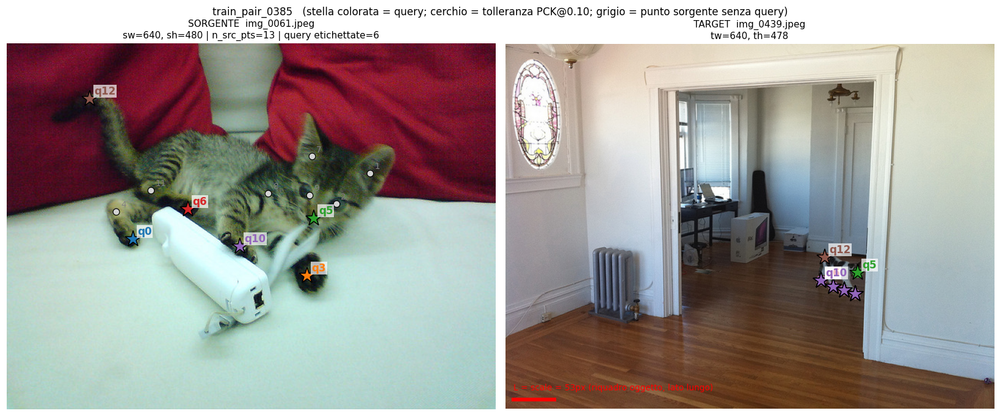

,id,query_index,source_x,source_y,scale,rel_scale,n_targets,targets
0,train_q_02450,0,165.00,256.0,53.39,0.08,4,"[[413.27763496143956, 309.5398457583548], [443..."
1609,train_q_02448,3,393.00,304.0,53.39,0.08,4,"[[413.27763496143956, 309.5398457583548], [443..."
466,train_q_02447,5,402.00,229.0,53.39,0.08,1,"[[461.0488431876607, 299.5398457583548]]"
370,train_q_02451,6,237.00,217.0,53.39,0.08,4,"[[413.27763496143956, 309.5398457583548], [443..."
2410,train_q_02449,10,305.00,266.0,53.39,0.08,4,"[[413.27763496143956, 309.5398457583548], [443..."
1403,train_q_02452,12,107.94,72.3,53.39,0.08,1,"[[418.0, 279.0]]"


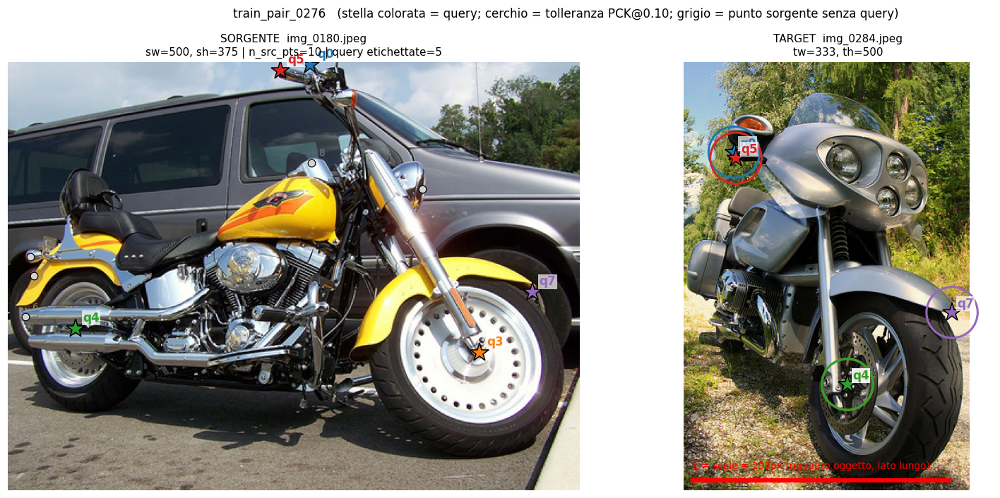

,id,query_index,source_x,source_y,scale,rel_scale,n_targets,targets
749,train_q_01708,0,264.00,2.00,298.1,0.6,1,"[[58.500000000000014, 105.0]]"
607,train_q_01711,3,412.05,253.89,298.1,0.6,1,"[[190.5, 376.0]]"
120,train_q_01712,4,59.05,232.89,298.1,0.6,1,"[[190.5, 376.0]]"
294,train_q_01709,5,238.00,7.00,298.1,0.6,1,"[[60.500000000000014, 112.0]]"
1,train_q_01710,7,458.05,200.89,298.1,0.6,1,"[[312.5, 292.0]]"


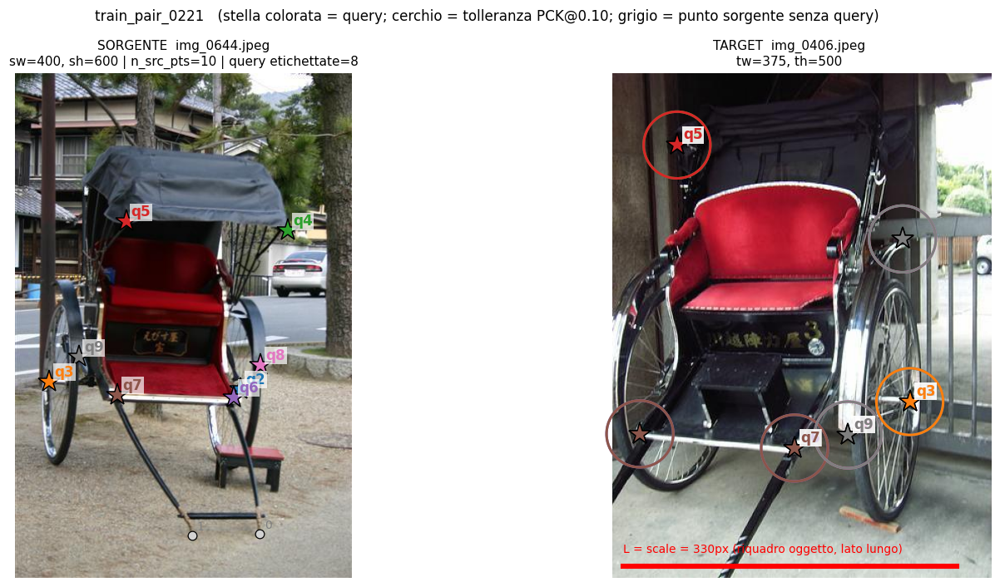

,id,query_index,source_x,source_y,scale,rel_scale,n_targets,targets
2,train_q_01371,2,267.00,375.00,330.0,0.66,1,"[[293.5, 325.0]]"
315,train_q_01372,3,40.00,366.00,330.0,0.66,1,"[[293.5, 325.0]]"
756,train_q_01369,4,323.00,187.00,330.0,0.66,1,"[[63.22340425531914, 71.0]]"
158,train_q_01370,5,131.00,176.00,330.0,0.66,1,"[[63.22340425531914, 71.0]]"
1170,train_q_01375,6,259.00,385.00,330.0,0.66,2,"[[179.5, 371.0], [26.5, 357.0]]"
196,train_q_01376,7,121.00,382.00,330.0,0.66,2,"[[179.5, 371.0], [26.5, 357.0]]"
2319,train_q_01373,8,290.92,346.29,330.0,0.66,2,"[[232.5, 358.0], [286.27348066298345, 164.0]]"
944,train_q_01374,9,75.00,337.00,330.0,0.66,2,"[[232.5, 358.0], [286.27348066298345, 164.0]]"


In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from PIL import Image

def show_pair(pid, split="train", max_q=None):
    df, pairs = (tr, PAIRS_TR) if split == "train" else (te, PAIRS_TE)
    meta = pairs[pid]
    g = df[df.pair_id == pid].sort_values("query_index")
    if max_q: g = g.head(max_q)
    cmap = plt.get_cmap("tab10")

    fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
    ax[0].imshow(Image.open(f"{DATA_DIR}/{meta['source_image']}"))
    ax[1].imshow(Image.open(f"{DATA_DIR}/{meta['target_image']}"))

    # 1) TUTTI i punti sorgente del JSON (source_xy): quelli senza query sono solo "contesto" (grigio)
    labeled = set(g.query_index)
    for k, (x, y) in enumerate(meta["source_xy"]):
        if k not in labeled:
            ax[0].plot(x, y, "o", ms=7, color="lightgray", mec="k", mew=.8)
            ax[0].text(x + 6, y - 6, f"{k}", color="gray", fontsize=9)

    # 2) Query etichettate: stella sorgente + target accettati (stelle + cerchio di tolleranza 0.10*scale)
    for i, r in enumerate(g.itertuples()):
        c = cmap(i % 10)
        ax[0].plot(r.source_x, r.source_y, "*", ms=18, color=c, mec="k", mew=1)
        ax[0].text(r.source_x + 6, r.source_y - 6, f"q{r.query_index}", color=c, weight="bold", fontsize=11,
                   bbox=dict(fc="white", ec="none", alpha=.7, pad=1))
        if split == "train":
            for t in r.targets:
                ax[1].plot(t[0], t[1], "*", ms=18, color=c, mec="k", mew=1)
                ax[1].add_patch(Circle(t, 0.10 * r.scale, fill=False, color=c, lw=2))     # raggio di tolleranza
            ax[1].text(r.targets[0][0] + 6, r.targets[0][1] - 6, f"q{r.query_index}", color=c, weight="bold", fontsize=11,
                       bbox=dict(fc="white", ec="none", alpha=.7, pad=1))

    # 3) Cornice dell'immagine (sw,sh / tw,th) e scala L come segmento di riferimento
    if split == "train":
        r0 = g.iloc[0]
        ax[1].plot([10, 10 + r0.scale], [meta["target_size"][1] - 12] * 2, "-", color="red", lw=4)
        ax[1].text(10, meta["target_size"][1] - 25, f"L = scale = {r0.scale:.0f}px (riquadro oggetto, lato lungo)", color="red", fontsize=9)

    s_w, s_h = meta["source_size"]; t_w, t_h = meta["target_size"]
    ax[0].set_title(f"SORGENTE  {meta['source_image'].split('/')[-1]}\nsw={s_w}, sh={s_h} | n_src_pts={len(meta['source_xy'])} "
                    f"| query etichettate={len(labeled)}", fontsize=10)
    ax[1].set_title(f"TARGET  {meta['target_image'].split('/')[-1]}\ntw={t_w}, th={t_h}", fontsize=10)
    for a in ax: a.axis("off")
    plt.suptitle(f"{pid}   (stella colorata = query; cerchio = tolleranza PCK@0.10; grigio = punto sorgente senza query)", fontsize=11)
    plt.tight_layout(); plt.show()

    # tabella dei dati mostrati
    cols = ["id", "query_index", "source_x", "source_y", "scale", "rel_scale", "n_targets", "targets"] if split == "train" else \
           ["id", "query_index", "source_x", "source_y"]
    display(g[cols].round(2))

for pid in tr.pair_id.unique()[:3]:
    show_pair(pid)

In [4]:
# ---- split per componenti connesse di immagini (union-find) ----
def components(df):
    parent = {}
    def find(a):
        parent.setdefault(a, a)
        while parent[a] != a: parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for s, t in set(zip(df.source_image, df.target_image)): parent[find(s)] = find(t)
    return df.source_image.map(find)
tr["comp"] = components(tr); te["comp"] = components(te)
rng = np.random.RandomState(SEED); comps = tr.comp.unique(); rng.shuffle(comps)
# riempie la validazione di componenti finché non si raggiunge VAL_FRAC delle query
val_c, n = set(), 0
for c in comps:
    if n >= VAL_FRAC * len(tr): break
    val_c.add(c); n += (tr.comp == c).sum()
tr["is_val"] = tr.comp.isin(val_c)
imgs_val = set(tr[tr.is_val].source_image) | set(tr[tr.is_val].target_image); imgs_trn = set(tr[~tr.is_val].source_image) | set(tr[~tr.is_val].target_image)
assert not (imgs_val & imgs_trn), "leakage: immagini condivise tra train e val"
print(f"componenti train={tr.comp.nunique()}  | query train-split={int((~tr.is_val).sum())}  val-split={int(tr.is_val.sum())}  | immagini condivise: 0 ✔")

componenti train=142  | query train-split=1800  val-split=695  | immagini condivise: 0 ✔


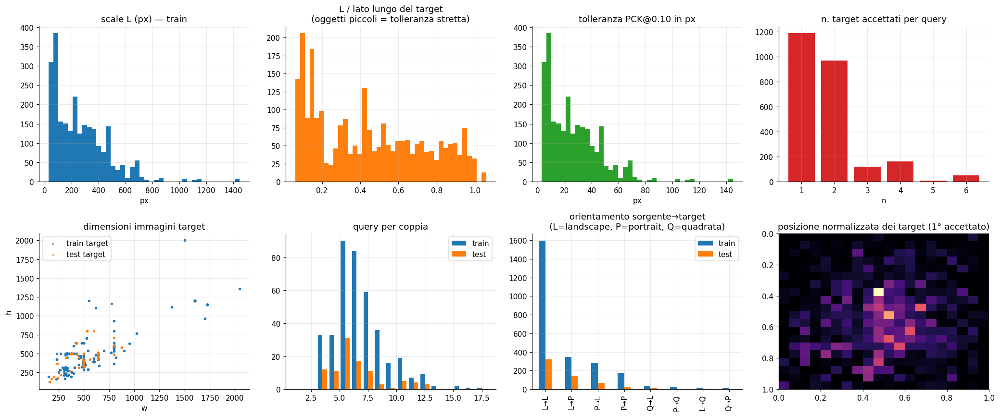

query con >1 target accettati: 52.5% | immagini riusate in più coppie (train): 27.7%


In [5]:
fig, ax = plt.subplots(2, 4, figsize=(19, 8))
ax = ax.ravel()
ax[0].hist(tr.scale, 40, color="C0"); ax[0].set_title("scale L (px) — train"); ax[0].set_xlabel("px")
ax[1].hist(tr.rel_scale, 40, color="C1"); ax[1].set_title("L / lato lungo del target\n(oggetti piccoli = tolleranza stretta)")
ax[2].hist(0.10 * tr.scale, 40, color="C2"); ax[2].set_title("tolleranza PCK@0.10 in px"); ax[2].set_xlabel("px")
vc = tr.n_targets.value_counts().sort_index(); ax[3].bar(vc.index, vc.values, color="C3"); ax[3].set_title("n. target accettati per query"); ax[3].set_xlabel("n")
for a_, (d, nm) in zip((ax[4], ax[5]), ((tr, "train"), (te, "test"))):
    pass
ax[4].scatter(tr.tw, tr.th, s=6, alpha=.4, label="train target"); ax[4].scatter(te.tw, te.th, s=6, alpha=.4, label="test target"); ax[4].set_title("dimensioni immagini target"); ax[4].set_xlabel("w"); ax[4].set_ylabel("h"); ax[4].legend()
qp = pd.concat([tr.groupby("pair_id").size().rename("train"), te.groupby("pair_id").size().rename("test")], axis=1)
ax[5].hist([qp.train.dropna(), qp.test.dropna()], bins=range(1, 19), label=["train", "test"]); ax[5].set_title("query per coppia"); ax[5].legend()
ori = lambda d: pd.Series(np.char.add(np.char.add(np.where(d.sw > d.sh, "L", np.where(d.sw < d.sh, "P", "Q")), "→"), np.where(d.tw > d.th, "L", np.where(d.tw < d.th, "P", "Q"))), index=d.index)
oc = pd.concat([ori(tr).value_counts().rename("train"), ori(te).value_counts().rename("test")], axis=1).fillna(0)
oc.plot.bar(ax=ax[6]); ax[6].set_title("orientamento sorgente→target\n(L=landscape, P=portrait, Q=quadrata)")
# densità posizioni normalizzate
sx, sy = tr.source_x / tr.sw, tr.source_y / tr.sh
tx = np.array([t[0] / w for ts, w in zip(tr.targets, tr.tw) for t in ts[:1]]); ty = np.array([t[1] / h for ts, h in zip(tr.targets, tr.th) for t in ts[:1]])
ax[7].hist2d(tx, ty, bins=20, range=[[0, 1], [0, 1]], cmap="magma"); ax[7].invert_yaxis(); ax[7].set_title("posizione normalizzata dei target (1° accettato)"); ax[7].grid(False)
plt.tight_layout(); plt.show()
print(f"query con >1 target accettati: {(tr.n_targets>1).mean():.1%} | immagini riusate in più coppie (train): "
      f"{(pd.concat([tr.drop_duplicates('pair_id').source_image, tr.drop_duplicates('pair_id').target_image]).value_counts()>1).mean():.1%}")

### 2.1 Esempi: cosa deve fare il modello
Cerchio verde tratteggiato = zona accettata (raggio $0.10\,L$ attorno a *ogni* target). Nel test i cerchi non esistono: il raggio dipende dall'oggetto, che non conosciamo.

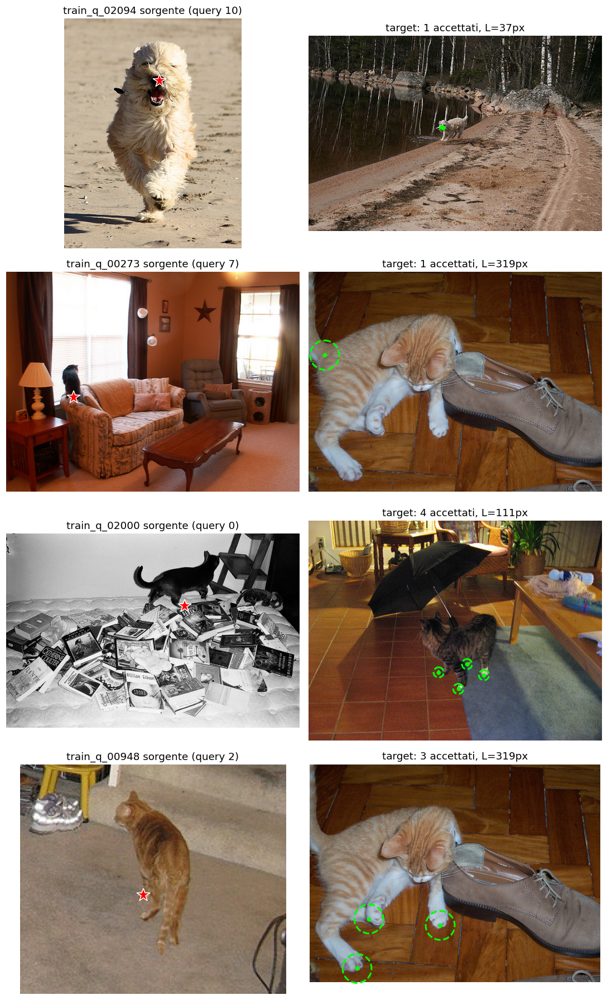

In [6]:
def load_img(split_df_row_path): return Image.open(f"{DATA_DIR}/{split_df_row_path}").convert("RGB")
def draw_circles(ax, pts, r, **kw):
    for p in pts: ax.add_patch(plt.Circle(p, r, fill=False, **kw)); ax.plot(*p, "o", color=kw.get("color", "lime"), ms=4)

def show_examples(df, idx, title=""):
    fig, axs = plt.subplots(len(idx), 2, figsize=(10, 4.1 * len(idx)))
    axs = np.atleast_2d(axs)
    for k, i in enumerate(idx):
        r = df.loc[i]
        if DRY_RUN or not os.path.exists(f"{DATA_DIR}/{r.source_image}"):
            si, ti = Image.new("RGB", (int(r.sw), int(r.sh)), (90, 90, 90)), Image.new("RGB", (int(r.tw), int(r.th)), (90, 90, 90))
        else: si, ti = load_img(r.source_image), load_img(r.target_image)
        axs[k, 0].imshow(si); axs[k, 0].plot(r.source_x, r.source_y, "r*", ms=16, mec="w"); axs[k, 0].set_title(f"{r.id} sorgente (query {r.query_index})")
        axs[k, 1].imshow(ti); draw_circles(axs[k, 1], r.targets, 0.10 * r.scale, color="lime", ls="--", lw=2)
        axs[k, 1].set_title(f"target: {r.n_targets} accettati, L={r.scale:.0f}px");
        for a in axs[k]: a.axis("off")
    plt.tight_layout(); plt.show()
ex = list(tr[tr.n_targets == 1].sample(2, random_state=1).index) + list(tr[tr.n_targets >= 3].sample(2, random_state=1).index)
show_examples(tr, ex)

## 3. Metrica, baseline banali, intervalli di confidenza
`metric.py` ufficiale non è stato fornito in questa consegna: sotto c'è l'implementazione dalla definizione del README (distanza al target accettato più vicino / `scale`, corretto se $\le 0.10$). **Se hai `metric.py`, confrontalo con `pck()` su qualche predizione**: l'unico dettaglio non specificato è `<` vs `≤` sul bordo.

Oltre al PCK@0.10 della leaderboard riportiamo:
* **PCK@0.05 / @0.20** — quanto siamo precisi / quanto sbagliamo "di poco";
* **errore normalizzato medio e mediano** $e=d/L$ — una misura continua senza il gradino della soglia;
* **PCK per fascia** (scala dell'oggetto, n. target, orientamento) — dove falliamo;
* **IC 95% con bootstrap per coppia** — le query della stessa coppia sono correlate, quindi si ricampionano le *coppie*; con ~600 query in validazione differenze < 2–3 punti non sono significative.

In [7]:
def norm_err(pred, targets, scale):
    # distanza dal target accettato più vicino, divisa per la scala dell'oggetto
    return float(np.linalg.norm(np.asarray(targets, float) - np.asarray(pred, float)[None], axis=1).min() / scale)

def pck(errs, thr=0.10):
    e = np.asarray(errs, float); e = e[~np.isnan(e)]
    return float((e <= thr).mean())

def boot_ci(errs, groups, thr=0.10, B=1000, seed=0):
    # IC 95% ricampionando i gruppi (coppie)
    e = pd.Series(np.asarray(errs, float)); g = pd.Series(np.asarray(groups)); ok = e.notna().values; e, g = e[ok], g[ok]
    ids = g.unique(); by = {k: (v.values <= thr) for k, v in e.groupby(g.values)}; r = np.random.RandomState(seed); out = []
    for _ in range(B):
        s = r.choice(len(ids), len(ids)); v = np.concatenate([by[ids[i]] for i in s]); out.append(v.mean())
    return np.percentile(out, [2.5, 97.5])

# ---- registro risultati: errori per query (allineati a tr.index; NaN = non valutata) ----
RESULTS = OrderedDict()
def register(name, preds_xy, df=None, meta=None):
    # preds_xy: DataFrame index=tr.index con colonne x,y (solo query valutate)
    df = tr if df is None else df
    e = pd.Series(np.nan, index=tr.index)
    for i, r in preds_xy.iterrows(): e[i] = norm_err((r.x, r.y), tr.targets[i], tr.scale[i])
    RESULTS[name] = dict(err=e, pred=preds_xy, meta=meta or {})
    return e

def summarize(names=None, subset="val"):
    rows = []
    for n in (names or RESULTS):
        e = RESULTS[n]["err"]; m = tr.is_val if subset == "val" else pd.Series(True, index=tr.index)
        ee = e[m]; ok = ee.notna()
        if ok.sum() == 0: continue
        lo, hi = boot_ci(ee[ok], tr.pair_id[m][ok])
        rows.append(dict(method=n, n=int(ok.sum()), **{f"PCK@{t:.2f}": pck(ee[ok], t) for t in PCK_THRS}, CI95_10=f"[{lo:.3f},{hi:.3f}]",
                         err_mean=ee[ok].mean(), err_median=ee[ok].median()))
    return pd.DataFrame(rows).set_index("method")

In [8]:
# ---- baseline banali: nessuna immagine, solo geometria ----
def baseline_preds(kind):
    out = {}
    mean_rel = np.array([np.mean([t[0] / w for ts, w in zip(tr[~tr.is_val].targets, tr[~tr.is_val].tw) for t in ts]),
                         np.mean([t[1] / h for ts, h in zip(tr[~tr.is_val].targets, tr[~tr.is_val].th) for t in ts])])
    for i, r in tr.iterrows():
        if kind == "centro":               out[i] = (r.tw / 2, r.th / 2)
        elif kind == "stessa pos. relativa": out[i] = (r.source_x / r.sw * r.tw, r.source_y / r.sh * r.th)
        elif kind == "media dei target":   out[i] = (mean_rel[0] * r.tw, mean_rel[1] * r.th)
    return pd.DataFrame(out, index=["x", "y"]).T
for k in ("centro", "stessa pos. relativa", "media dei target"):
    register(f"baseline: {k}", baseline_preds(k))
display(summarize().style.format(precision=3))

,n,PCK@0.05,PCK@0.10,PCK@0.20,CI95_10,err_mean,err_median
method,,,,,,,
baseline: centro,695,0.000,0.047,0.137,"[0.022,0.077]",0.527,0.450
baseline: stessa pos. relativa,695,0.003,0.022,0.081,"[0.010,0.036]",1.019,0.617
baseline: media dei target,695,0.009,0.016,0.114,"[0.003,0.031]",0.592,0.461


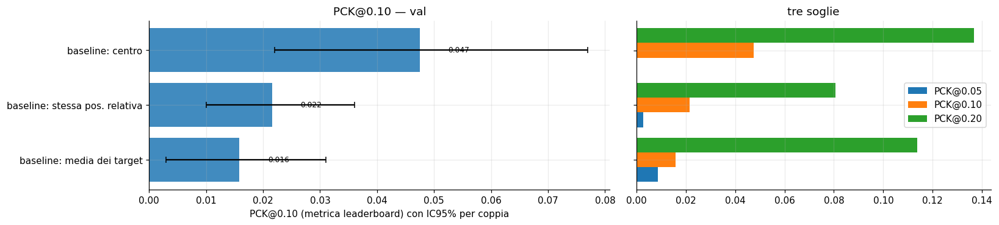

In [9]:
def plot_summary(names=None, subset="val", title=""):
    t = summarize(names, subset); fig, ax = plt.subplots(1, 2, figsize=(15, 0.42 * len(t) + 2.2), gridspec_kw={"width_ratios": [1.3, 1]})
    ci = np.array([[float(x) for x in s.strip("[]").split(",")] for s in t.CI95_10]); y = np.arange(len(t))[::-1]
    ax[0].barh(y, t["PCK@0.10"], xerr=[t["PCK@0.10"] - ci[:, 0], ci[:, 1] - t["PCK@0.10"]], color="C0", alpha=.85, capsize=3)
    ax[0].set_yticks(y); ax[0].set_yticklabels(t.index); ax[0].set_xlabel("PCK@0.10 (metrica leaderboard) con IC95% per coppia"); ax[0].set_title(title or f"PCK@0.10 — {subset}")
    for yy, v in zip(y, t["PCK@0.10"]): ax[0].text(v + .005, yy, f"{v:.3f}", va="center", fontsize=8)
    w = .27
    for j, c in enumerate(["PCK@0.05", "PCK@0.10", "PCK@0.20"]): ax[1].barh(y + (j - 1) * w, t[c], w, label=c)
    ax[1].set_yticks(y); ax[1].set_yticklabels([]); ax[1].legend(); ax[1].set_title("tre soglie")
    plt.tight_layout(); plt.show()
plot_summary()

Le baseline "solo geometria" fissano il pavimento: quanto si ottiene *senza guardare i pixel*. Ogni metodo successivo deve batterle di molto per avere senso.

## 4. Estrattore di feature (DINOv2 / DINOv3)
* l'immagine viene ridimensionata **mantenendo le proporzioni** (lato lungo = `size`, lati arrotondati a multipli della patch) → niente deformazioni come nel notebook sui gatti;
* le feature di patch sono L2-normalizzate; si possono combinare più layer (media delle feature normalizzate);
* `feats(path, flip)` restituisce `(C, gh, gw)` + metadati; cache su disco in `WORK_DIR/feat_cache`;
* **convenzione coordinate**: la patch $(i,j)$ ha centro $((j+\tfrac12)P,(i+\tfrac12)P)$ nell'immagine ridimensionata, quindi $x_{orig}=(j+\tfrac12)\,W/g_w$. Il punto sorgente si legge per **interpolazione bilineare** sulla griglia (non "patch più vicina").
* `DRY_RUN=1` usa un backend finto (proiezione casuale dei colori) per testare l'intera pipeline senza modelli.

In [10]:
IMNET_MEAN = np.array([0.485, 0.456, 0.406], np.float32); IMNET_STD = np.array([0.229, 0.224, 0.225], np.float32)
_MODELS = {}; _MEM = OrderedDict(); _MEM_MAX = 256

def _load_hf(model_id):
    if model_id in _MODELS: return _MODELS[model_id]
    from transformers import DINOv3ViTConfig, DINOv3ViTModel
    cfg = DINOv3ViTConfig(hidden_size=768, intermediate_size=3072, num_hidden_layers=12,
                          num_attention_heads=12, patch_size=16, num_register_tokens=4)
    m = DINOv3ViTModel(cfg)
    sd = torch.load(DINO_WEIGHTS, map_location="cpu")
    sd = sd.get("state_dict", sd) if isinstance(sd, dict) else sd
    sd = {("model." + k if k.startswith("layer.") else k): v for k, v in sd.items()}
    miss, unexp = m.load_state_dict(sd, strict=False)
    print("chiavi mancanti:", miss, "| inattese:", unexp)
    assert not [k for k in miss if "layer" in k or "embeddings" in k], "pesi non caricati!"
    m = m.to(DEVICE).eval()
    if DEVICE == "cuda": m = m.half()
    _MODELS[model_id] = m; return m

class Extractor:
    # feature dense L2-normalizzate. layers: indici degli hidden_states (-1 = ultimo, già con LayerNorm)
    def __init__(self, model_id, size=IMG_SIZE, layers=(-1,), name=None):
        self.model_id, self.size, self.layers = model_id, size, tuple(layers)
        self.name = name or f"{model_id.split('/')[-1]}@{size}" + ("" if self.layers == (-1,) else f"|L{list(self.layers)}")
        if DRY_RUN: self.P = 16
        else: self.P = int(getattr(_load_hf(model_id).config, "patch_size", 16))
        self._rp = np.random.RandomState(0).randn(3 * 4, 64).astype(np.float32) if DRY_RUN else None

    def grid(self, W, H):
        s = self.size / max(W, H); P = self.P
        return max(1, round(H * s / P)), max(1, round(W * s / P))              # gh, gw

    def feats(self, path, flip=False):
        key = (path, self.model_id, self.size, self.layers, flip, DRY_RUN)
        if key in _MEM: _MEM.move_to_end(key); return _MEM[key]
        fn = f"{WORK_DIR}/feat_cache/" + hashlib.md5(repr(key).encode()).hexdigest() + ".npy"
        if os.path.exists(fn): out = np.load(fn)
        else:
            out = self._compute(path, flip); np.save(fn, out.astype(np.float16))
        out = out.astype(np.float32)
        _MEM[key] = out
        if len(_MEM) > _MEM_MAX: _MEM.popitem(last=False)
        return out

    def _open(self, path):
        full = f"{DATA_DIR}/{path}"
        if os.path.exists(full): return Image.open(full).convert("RGB")
        # DRY_RUN: immagine sintetica con la dimensione giusta (deterministica)
        W, H = SIZES[path]; r = np.random.RandomState(abs(hash(path)) % 2**31)
        base = ndi.zoom(r.rand(6, 6, 3), (H / 6, W / 6, 1), order=1)[:H, :W]; return Image.fromarray((base * 255).astype(np.uint8))

    def _compute(self, path, flip):
        img = self._open(path); W, H = img.size; gh, gw = self.grid(W, H); P = self.P
        img = img.resize((gw * P, gh * P), Image.BICUBIC)
        if flip: img = ImageOps.mirror(img)
        x = np.asarray(img, np.float32) / 255.0
        if DRY_RUN:   # feature finte: colori + gradienti locali proiettati a caso
            xs = ndi.uniform_filter(x, (P, P, 1))[P // 2::P, P // 2::P][:gh, :gw]
            gx, gy = np.gradient(xs.mean(-1)); f = np.concatenate([xs, gx[..., None].repeat(3, -1), gy[..., None].repeat(3, -1), xs ** 2], -1) @ self._rp
            f = f / (np.linalg.norm(f, axis=-1, keepdims=True) + 1e-8); return f.transpose(2, 0, 1)
        x = torch.from_numpy(((x - IMNET_MEAN) / IMNET_STD).transpose(2, 0, 1))[None].to(DEVICE)
        m = _load_hf(self.model_id); x = x.half() if DEVICE == "cuda" else x
        with torch.no_grad():
            o = m(pixel_values=x, output_hidden_states=True)
            fs = []
            for l in self.layers:
                h = o.last_hidden_state if l == -1 else o.hidden_states[l]
                h = h[0, -gh * gw:].float()                                     # scarta CLS e register tokens
                fs.append(torch.nn.functional.normalize(h, dim=-1).reshape(gh, gw, -1))
            f = torch.nn.functional.normalize(torch.cat(fs, -1), dim=-1)
        return f.permute(2, 0, 1).cpu().numpy()

# dimensioni immagini (solo per DRY_RUN senza file)
SIZES = {}
for d in (tr, te):
    for r in d.itertuples(): SIZES[r.source_image] = (r.sw, r.sh); SIZES[r.target_image] = (r.tw, r.th)

def get_main_extractor(size=IMG_SIZE, layers=(-1,)):
    if DRY_RUN: return Extractor("dry", size, layers)
    try: return Extractor(MODEL_MAIN, size, layers)
    except Exception as e:
        print(f"⚠ {MODEL_MAIN} non caricabile ({type(e).__name__}: {str(e)[:90]}) → fallback {MODEL_FALLBACK}")
        return Extractor(MODEL_FALLBACK, size, layers)
EXT = get_main_extractor(); print("estrattore principale:", EXT.name, "| patch", EXT.P)

chiavi mancanti: [] | inattese: []
estrattore principale: local-dinov3-vitb16@448 | patch 16


## 5. Matching
### 5.1 Mappa di similarità
Per un punto sorgente $p$: $f_s=\text{bilinear}(F_s,p)$ (normalizzato) → mappa $S(i,j)=\langle f_s,F_t(i,j)\rangle$ (coseno).

### 5.2 Mappa canonica e decoding sub-patch
Le mappe di modelli/risoluzioni diversi vivono su griglie diverse: si ricampionano (spline cubica) su una **griglia canonica** fine (lato lungo `CANON` celle) → si possono mediare (ensemble) e decodificare con precisione sub-patch:
* `argmax` — cella più alta;
* `soft` — baricentro pesato $\exp(S/\tau)$ in una finestra attorno al picco (corregge la quantizzazione, ma non può spostare un picco sulla regione sbagliata).

### 5.3 TTA con specchio
Si specchiano **entrambe** le immagini (sorgente e target) e si specchia indietro la mappa. (Specchiare solo il target scambierebbe sinistra/destra: parti simmetriche, come occhio sx/dx, verrebbero confuse.)

### 5.4 Ri-ranking geometrico (idea dal paper di Qian et al.)
I **punti sorgente non-query** della stessa coppia sono noti anche nel test. Per ogni punto $i$: si abbinano gli altri punti, si stima con IRLS una trasformazione **affine pesata** (pesi gaussiani sulla distanza sorgente, robusta agli outlier) dai loro match, e si predice dove dovrebbe cadere $i$. Fra i $K$ picchi candidati della mappa si sceglie quello che massimizza
$$ \text{score}(c)=S(c)-\lambda\,\frac{\|c-\hat p^{aff}_i\|}{\max(W_t,H_t)} .$$
Risolve le ambiguità di parti ripetute/simmetriche e i match su sfondo, quando gli altri punti sono sensati.

In [11]:
CANON = 112   # celle sul lato lungo della mappa canonica

def bilinear(F, u, v):
    # F (C,gh,gw); u,v coordinate continue in indice-griglia (centro patch j = indice j)
    C, gh, gw = F.shape; u = np.clip(u, 0, gw - 1); v = np.clip(v, 0, gh - 1)
    u0, v0 = int(np.floor(u)), int(np.floor(v)); u1, v1 = min(u0 + 1, gw - 1), min(v0 + 1, gh - 1); a, b = u - u0, v - v0
    return (F[:, v0, u0] * (1 - a) * (1 - b) + F[:, v0, u1] * a * (1 - b) + F[:, v1, u0] * (1 - a) * b + F[:, v1, u1] * a * b)

def sim_map(Fs, Ft, p, Ws, Hs):
    gh_s, gw_s = Fs.shape[1:]
    u, v = p[0] / Ws * gw_s - 0.5, p[1] / Hs * gh_s - 0.5                          # pixel orig → indice griglia
    f = bilinear(Fs, u, v); f = f / (np.linalg.norm(f) + 1e-8)
    return np.tensordot(f, Ft, axes=(0, 0))                                         # (gh_t, gw_t)

def to_canon(S, Hc, Wc, order=3):
    gh, gw = S.shape
    ii = (np.arange(Hc) + .5) / Hc * gh - .5; jj = (np.arange(Wc) + .5) / Wc * gw - .5
    return ndi.map_coordinates(S, np.meshgrid(ii, jj, indexing="ij"), order=order, mode="nearest")

def canon_shape(Wt, Ht): s = CANON / max(Wt, Ht); return max(2, round(Ht * s)), max(2, round(Wt * s))

def cell_to_xy(i, j, Hc, Wc, Wt, Ht): return (j + .5) / Wc * Wt, (i + .5) / Hc * Ht

def decode_argmax(S, Wt, Ht):
    i, j = np.unravel_index(np.argmax(S), S.shape); return cell_to_xy(i, j, *S.shape, Wt, Ht)

def decode_soft(S, Wt, Ht, tau=0.03, rad=6, center=None):
    Hc, Wc = S.shape; i0, j0 = center if center is not None else np.unravel_index(np.argmax(S), S.shape)
    i1, i2, j1, j2 = max(0, i0 - rad), min(Hc, i0 + rad + 1), max(0, j0 - rad), min(Wc, j0 + rad + 1)
    sub = S[i1:i2, j1:j2]; w = np.exp((sub - S[i0, j0]) / tau); w /= w.sum()
    ii, jj = np.meshgrid(np.arange(i1, i2), np.arange(j1, j2), indexing="ij")
    return cell_to_xy((w * ii).sum(), (w * jj).sum(), Hc, Wc, Wt, Ht)

def top_peaks(S, K=5, nms=6):
    S2 = S.copy(); out = []
    for _ in range(K):
        i, j = np.unravel_index(np.argmax(S2), S2.shape); out.append((i, j, S[i, j]))
        S2[max(0, i - nms):i + nms + 1, max(0, j - nms):j + nms + 1] = -np.inf
        if not np.isfinite(S2).any(): break
    return out

In [12]:
def weighted_affine(src, dst, w, ridge=1e-3):
    # minimi quadrati pesati: dst ≈ [x y 1] @ M ; ridge verso l'identità sulla parte lineare (stabilizza con pochi punti)
    A = np.c_[src, np.ones(len(src))]; Wd = np.diag(w)
    R = ridge * np.trace(A.T @ Wd @ A) / 3 * np.diag([1, 1, 0]); I0 = np.zeros((3, 2)); I0[0, 0] = I0[1, 1] = 1
    M = np.linalg.solve(A.T @ Wd @ A + R, A.T @ Wd @ dst + R @ I0); return M

def geom_predict(i, src_pts, match_pts, conf, Ws, Hs, sigma_frac=0.35, iters=3, tau_px=None):
    # predice dove cade il punto i usando match degli altri punti (affine pesata + IRLS); None se troppo pochi punti
    idx = [j for j in range(len(src_pts)) if j != i]
    if len(idx) < 3: return None
    S, D = src_pts[idx], match_pts[idx]; sig = sigma_frac * max(Ws, Hs)
    w0 = np.exp(-((S - src_pts[i]) ** 2).sum(1) / (2 * sig ** 2)) * np.clip(conf[idx], 1e-3, None)
    w = w0.copy(); tau = tau_px or 0.15 * max(Ws, Hs)
    for _ in range(iters):
        M = weighted_affine(S, D, w); res = np.linalg.norm(np.c_[S, np.ones(len(S))] @ M - D, axis=1); w = w0 / (1 + (res / tau) ** 2)
    return np.r_[src_pts[i], 1.0] @ M

In [13]:
def pair_maps(pair, extractors, flip=False):
    # per ogni punto sorgente della coppia: mappa canonica media su tutti gli estrattori (e TTA specchio)
    Ws, Hs = pair["source_size"]; Wt, Ht = pair["target_size"]; Hc, Wc = canon_shape(Wt, Ht)
    pts = np.asarray(pair["source_xy"], float); acc = np.zeros((len(pts), Hc, Wc), np.float32); n = 0
    for ex in extractors:
        for fl in ((False, True) if flip else (False,)):
            Fs, Ft = ex.feats(pair["source_image"], fl), ex.feats(pair["target_image"], fl)
            for k, p in enumerate(pts):
                q = np.array([Ws - p[0], p[1]]) if fl else p
                S = to_canon(sim_map(Fs, Ft, q, Ws, Hs), Hc, Wc)
                acc[k] += S[:, ::-1] if fl else S
            n += 1
    return acc / n

def predict_pair(pair, cfg, return_maps=False):
    # cfg: extractors (lista), flip, decode ('argmax'|'soft'), tau, rad, geom (None | dict(lam, K, sigma_frac))
    Wt, Ht = pair["target_size"]; Ws, Hs = pair["source_size"]; pts = np.asarray(pair["source_xy"], float)
    maps = pair_maps(pair, cfg["extractors"], cfg.get("flip", False))
    dec = (lambda S, c=None: decode_soft(S, Wt, Ht, cfg.get("tau", .03), cfg.get("rad", 6), c)) if cfg.get("decode", "argmax") == "soft" else (lambda S, c=None: decode_argmax(S, Wt, Ht))
    first = np.array([dec(S) for S in maps]); conf = maps.reshape(len(maps), -1).max(1)
    out = first.copy(); g = cfg.get("geom")
    if g:
        for i, S in enumerate(maps):
            pa = geom_predict(i, pts, first, conf, Ws, Hs, g.get("sigma_frac", .35))
            if pa is None: continue
            cands = top_peaks(S, g.get("K", 5), g.get("nms", 6)); Hc, Wc = S.shape
            sc = [s - g["lam"] * np.linalg.norm(np.array(cell_to_xy(ci, cj, Hc, Wc, Wt, Ht)) - pa) / max(Wt, Ht) for ci, cj, s in cands]
            ci, cj, _ = cands[int(np.argmax(sc))]
            out[i] = dec(S, (ci, cj)) if cfg.get("decode") == "soft" else cell_to_xy(ci, cj, Hc, Wc, Wt, Ht)
    return (out, maps) if return_maps else out

def run(name, cfg, df=None, max_pairs=EVAL_MAX_PAIRS, desc=None):
    # valuta su df (default: tutto il train); restituisce e registra gli errori
    df = tr if df is None else df; pids = list(df.pair_id.unique())
    if max_pairs: pids = pids[:max_pairs]
    rows = {}
    for pid in tqdm(pids, desc=desc or name, leave=False):
        out = predict_pair(PAIRS_TR[pid], cfg)
        for i, r in df[df.pair_id == pid].iterrows(): rows[i] = out[r.query_index]
    preds = pd.DataFrame(rows, index=["x", "y"]).T
    register(name, preds, meta=dict(cfg={k: (v if k != "extractors" else [e.name for e in v]) for k, v in cfg.items()}))
    return summarize([name]).iloc[0]

### 5.5 Sanity check: auto-matching
Se sorgente = target, la predizione deve cadere sul punto stesso (errore ≈ 0). Verifica la correttezza delle conversioni di coordinate (griglia ↔ pixel originali, bilineare, specchio).

In [14]:
r0 = tr.iloc[0]; pair = dict(PAIRS_TR[r0.pair_id]); pair["target_image"], pair["target_size"] = pair["source_image"], pair["source_size"]
for fl in (False, True):
    for dec in ("argmax", "soft"):
        out = predict_pair(pair, dict(extractors=[EXT], flip=fl, decode=dec)); pts = np.asarray(pair["source_xy"])
        d = np.linalg.norm(out - pts, axis=1) / max(pair["source_size"])
        print(f"flip={fl!s:5} decode={dec:6} errore medio/max (frazione del lato lungo): {d.mean():.4f} / {d.max():.4f}")
assert d.mean() < 0.03, "conversione coordinate sospetta!"

flip=False decode=argmax errore medio/max (frazione del lato lungo): 0.0134 / 0.0467
flip=False decode=soft   errore medio/max (frazione del lato lungo): 0.0100 / 0.0343
flip=True  decode=argmax errore medio/max (frazione del lato lungo): 0.0134 / 0.0467
flip=True  decode=soft   errore medio/max (frazione del lato lungo): 0.0097 / 0.0358


### 5.6 Cosa fa la mappa di similarità
Una query: mappa sul target, picco predetto (✕ rossa), target accettati (cerchi verdi).

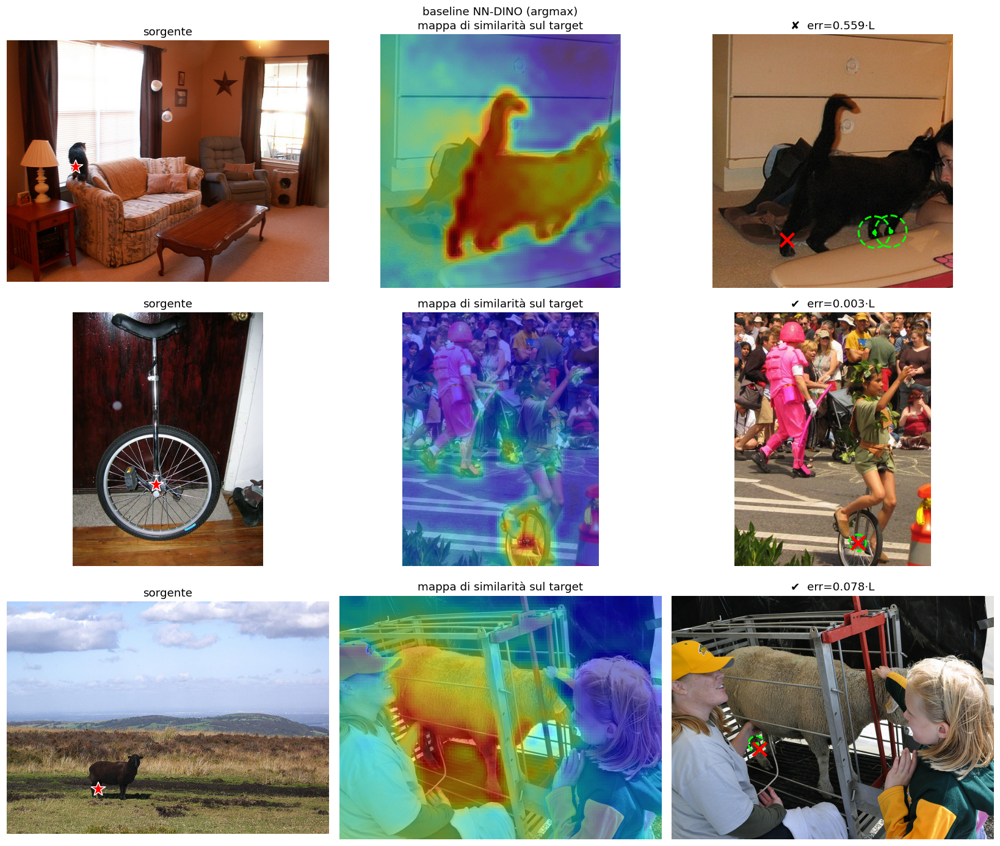

In [15]:
def show_maps(rows, cfg, title=""):
    n = len(rows); fig, axs = plt.subplots(n, 3, figsize=(15, 4.3 * n)); axs = np.atleast_2d(axs)
    for k, i in enumerate(rows):
        r = tr.loc[i]; pair = PAIRS_TR[r.pair_id]; out, maps = predict_pair(pair, cfg, return_maps=True)
        S = maps[r.query_index]; px, py = out[r.query_index]; e = norm_err((px, py), r.targets, r.scale)
        si, ti = EXT._open(r.source_image), EXT._open(r.target_image)
        axs[k, 0].imshow(si); axs[k, 0].plot(r.source_x, r.source_y, "r*", ms=16, mec="w"); axs[k, 0].set_title("sorgente")
        axs[k, 1].imshow(ti); axs[k, 1].imshow(S, extent=(0, r.tw, r.th, 0), cmap="jet", alpha=.5)
        axs[k, 1].set_title("mappa di similarità sul target")
        axs[k, 2].imshow(ti); draw_circles(axs[k, 2], r.targets, .1 * r.scale, color="lime", ls="--", lw=2); axs[k, 2].plot(px, py, "rx", ms=14, mew=3)
        axs[k, 2].set_title(f"{'✔' if e <= .1 else '✘'}  err={e:.3f}·L"); [a.axis("off") for a in axs[k]]
    plt.suptitle(title); plt.tight_layout(); plt.show()
base_cfg = dict(extractors=[EXT], decode="argmax")
show_maps(list(tr.sample(3, random_state=3).index), base_cfg, "baseline NN-DINO (argmax)")

## 6. Esperimenti
Tutti gli esperimenti training-free sono valutati su **tutto il train** (nessun parametro appreso). I metodi con iperparametri scelti sui dati (λ, τ) li scegliamo su `train-split` e li *riportiamo* su `val-split`; il confronto in tabella usa **val-split** per tutti, quindi i numeri sono confrontabili con l'adapter del §7.

Per esperimenti rapidi: `EVAL_MAX_PAIRS = 100` nel §1.

### A. Baseline DINO (NN + argmax)

B0 · NN argmax:   0%|          | 0/392 [00:00<?, ?it/s]

n                       695
PCK@0.05           0.079137
PCK@0.10           0.198561
PCK@0.20           0.444604
CI95_10       [0.165,0.233]
err_mean           0.358794
err_median         0.225087
Name: B0 · NN argmax, dtype: object


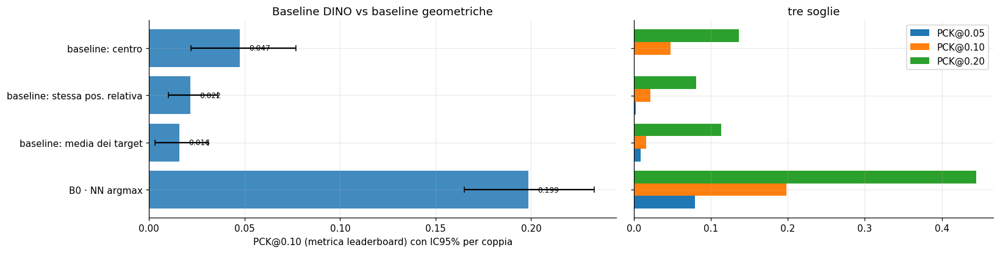

In [16]:
res = run("B0 · NN argmax", dict(extractors=[EXT], decode="argmax"))
print(res); plot_summary(title="Baseline DINO vs baseline geometriche")

### B. Decoding sub-patch (argmax vs soft-argmax)

B1 · soft τ=0.01 r=3:   0%|          | 0/392 [00:00<?, ?it/s]

B1 · soft τ=0.01 r=6:   0%|          | 0/392 [00:00<?, ?it/s]

B1 · soft τ=0.01 r=12:   0%|          | 0/392 [00:00<?, ?it/s]

B1 · soft τ=0.03 r=3:   0%|          | 0/392 [00:00<?, ?it/s]

B1 · soft τ=0.03 r=6:   0%|          | 0/392 [00:00<?, ?it/s]

B1 · soft τ=0.03 r=12:   0%|          | 0/392 [00:00<?, ?it/s]

B1 · soft τ=0.1 r=3:   0%|          | 0/392 [00:00<?, ?it/s]

B1 · soft τ=0.1 r=6:   0%|          | 0/392 [00:00<?, ?it/s]

B1 · soft τ=0.1 r=12:   0%|          | 0/392 [00:00<?, ?it/s]

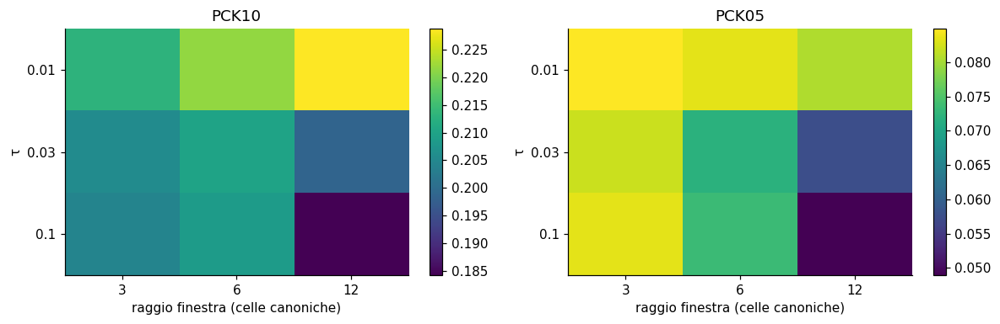

scelta: {'tau': 0.01, 'rad': 12}


In [17]:
rows = []
for tau in (0.01, 0.03, 0.1):
    for rad in (3, 6, 12):
        n = f"B1 · soft τ={tau} r={rad}"; run(n, dict(extractors=[EXT], decode="soft", tau=tau, rad=rad)); rows.append((tau, rad, summarize([n]).iloc[0]["PCK@0.10"], summarize([n]).iloc[0]["PCK@0.05"]))
g = pd.DataFrame(rows, columns=["tau", "rad", "PCK10", "PCK05"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, c in zip(ax, ("PCK10", "PCK05")):
    im = a.imshow(g.pivot(index="tau", columns="rad", values=c), cmap="viridis", aspect="auto"); a.set_xticks(range(3)); a.set_xticklabels(sorted(g.rad.unique())); a.set_yticks(range(3)); a.set_yticklabels(sorted(g.tau.unique()))
    a.set_xlabel("raggio finestra (celle canoniche)"); a.set_ylabel("τ"); a.set_title(c); a.grid(False); plt.colorbar(im, ax=a)
plt.tight_layout(); plt.show()
best = g.sort_values("PCK10", ascending=False).iloc[0]; SOFT = dict(tau=float(best.tau), rad=int(best.rad)); print("scelta:", SOFT)

### C. Risoluzione di input

C · size 224:   0%|          | 0/392 [00:00<?, ?it/s]

C · size 336:   0%|          | 0/392 [00:00<?, ?it/s]

C · size 448:   0%|          | 0/392 [00:00<?, ?it/s]

C · size 672:   0%|          | 0/392 [00:00<?, ?it/s]

C · size 896:   0%|          | 0/392 [00:00<?, ?it/s]

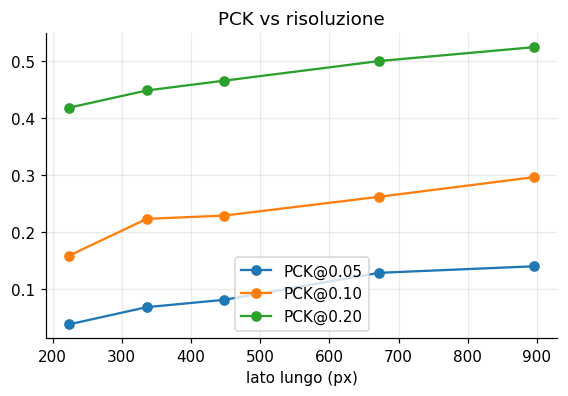

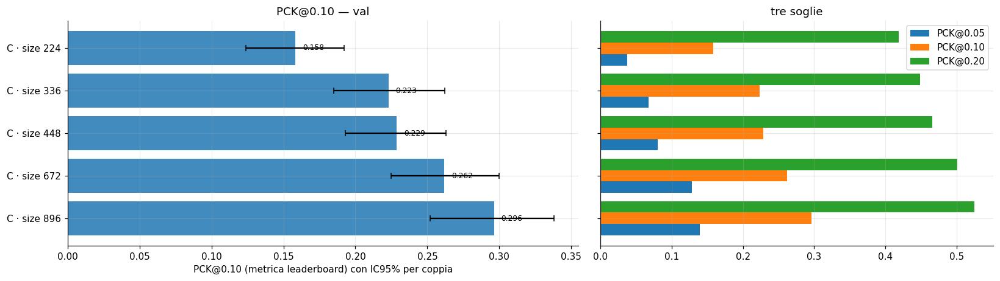

In [18]:
for s in (224, 336, 448, 672, 896):
    run(f"C · size {s}", dict(extractors=[get_main_extractor(s)], decode="soft", **SOFT))
cs = summarize([k for k in RESULTS if k.startswith("C ·")]); cs["size"] = [int(k.split()[-1]) for k in cs.index]
fig, ax = plt.subplots(figsize=(6, 3.6));
for c in ("PCK@0.05", "PCK@0.10", "PCK@0.20"): ax.plot(cs["size"], cs[c], "o-", label=c)
ax.set_xlabel("lato lungo (px)"); ax.set_title("PCK vs risoluzione"); ax.legend(); plt.show(); plot_summary([k for k in RESULTS if k.startswith("C ·")])

### D. Quali layer? (ultimo vs media di più layer)

D · layer ultimo:   0%|          | 0/392 [00:00<?, ?it/s]

D · layer ultimi 2:   0%|          | 0/392 [00:00<?, ?it/s]

D · layer ultimo+metà:   0%|          | 0/392 [00:00<?, ?it/s]

salto ultimo+metà tuple index out of range


D · layer ultimi 4:   0%|          | 0/392 [00:00<?, ?it/s]

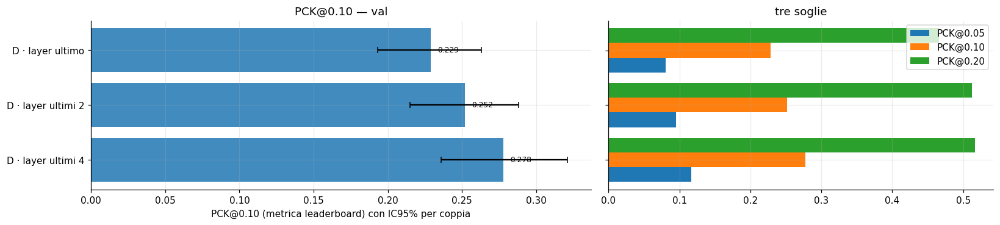

In [19]:
nl = 12 if "base" in EXT.model_id or DRY_RUN else 24
for name, ly in (("ultimo", (-1,)), ("ultimi 2", (-1, -2)), ("ultimo+metà", (-1, nl // 2 + 1)), ("ultimi 4", (-1, -2, -3, -4))):
    try: run(f"D · layer {name}", dict(extractors=[get_main_extractor(IMG_SIZE, ly)], decode="soft", **SOFT))
    except Exception as e: print("salto", name, e)
plot_summary([k for k in RESULTS if k.startswith("D ·")])

### E. TTA con specchio

E · flip TTA:   0%|          | 0/392 [00:00<?, ?it/s]

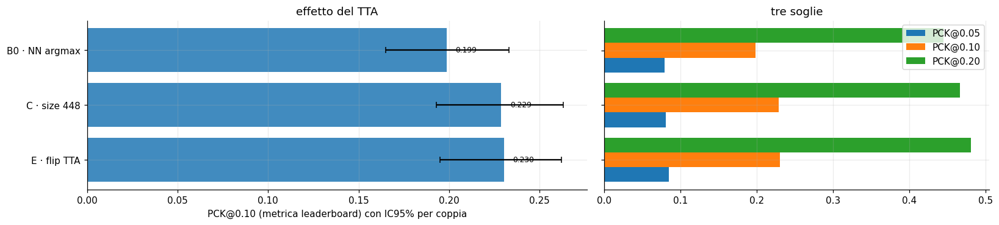

In [20]:
run("E · flip TTA", dict(extractors=[EXT], decode="soft", flip=True, **SOFT))
plot_summary(["B0 · NN argmax", "C · size 448", "E · flip TTA"], title="effetto del TTA")

### F. Altri backbone (DINOv2 vs DINOv3, base vs large)

F · local-dinov3-vitb16:   0%|          | 0/392 [00:00<?, ?it/s]

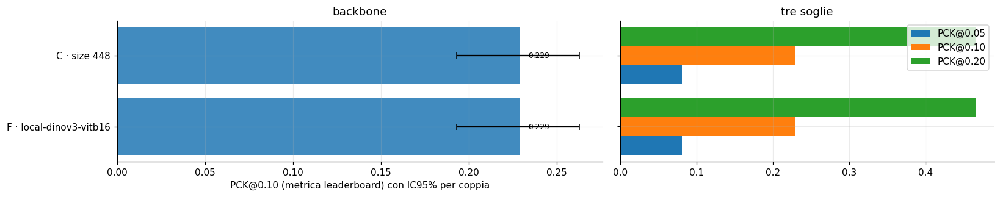

In [21]:
MODEL_EXT = {}
for mid in ([MODEL_FALLBACK] + EXTRA_MODELS) if not DRY_RUN else []:
    try: MODEL_EXT[mid] = Extractor(mid, IMG_SIZE); run(f"F · {mid.split('/')[-1]}", dict(extractors=[MODEL_EXT[mid]], decode="soft", **SOFT))
    except Exception as e: print(f"⚠ salto {mid}: {type(e).__name__}: {str(e)[:100]}")
plot_summary([k for k in RESULTS if k.startswith("F ·") or k == "C · size 448"], title="backbone")

### G. Ensemble di mappe (più modelli / più risoluzioni)

G · ensemble multi-res/multi-modello:   0%|          | 0/392 [00:00<?, ?it/s]

G · ensemble + flip:   0%|          | 0/392 [00:00<?, ?it/s]

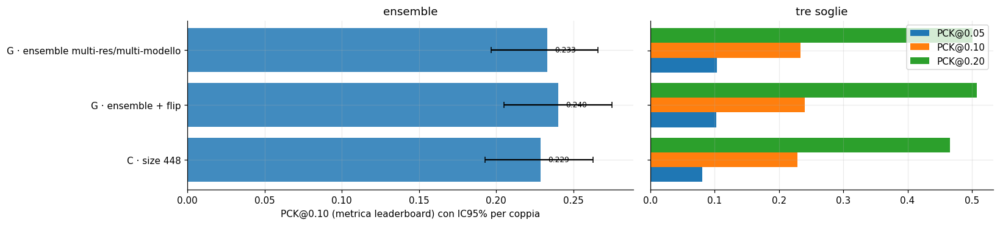

In [22]:
ens_ex = [EXT, get_main_extractor(672)] + list(MODEL_EXT.values())[:2]
run("G · ensemble multi-res/multi-modello", dict(extractors=ens_ex, decode="soft", **SOFT))
run("G · ensemble + flip", dict(extractors=ens_ex, decode="soft", flip=True, **SOFT))
plot_summary([k for k in RESULTS if k.startswith("G ·")] + ["C · size 448"], title="ensemble")

### H. Dove si sbaglia davvero? (diagnostica sul miglior metodo finora)
Per i metodi training-free la parte interessante è **come** fallisce: picco vicino ma impreciso (errore 0.1–0.2), parte sbagliata dello stesso oggetto, istanza sbagliata (multi-oggetto), sfondo. Se quasi tutto è "vicino ma impreciso", servono risoluzione/decoding; se è "parte sbagliata/simmetria", serve la geometria (I) o un adapter (J).

miglior metodo finora (val): C · size 896


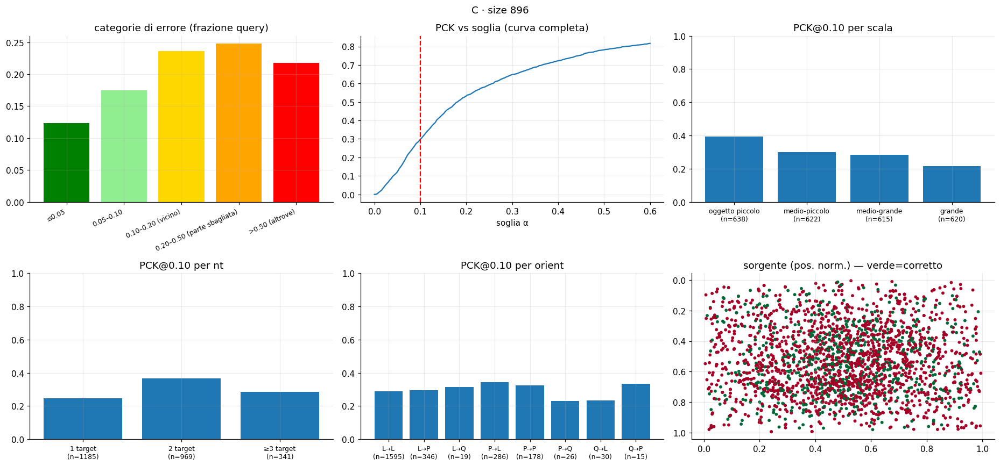

In [23]:
def best_name(prefixes=None, subset="val"):
    t = summarize([k for k in RESULTS if not k.startswith("baseline")], subset); return t["PCK@0.10"].idxmax()
BEST = best_name(); print("miglior metodo finora (val):", BEST)
def diagnostics(name):
    e = RESULTS[name]["err"]; m = e.notna(); d = tr[m].copy(); d["e"] = e[m]
    d["cat"] = pd.cut(d.e, [-1, .05, .10, .20, .50, 1e9], labels=["≤0.05", "0.05–0.10", "0.10–0.20 (vicino)", "0.20–0.50 (parte sbagliata)", ">0.50 (altrove)"])
    d["scala"] = pd.qcut(d.rel_scale, 4, labels=["oggetto piccolo", "medio-piccolo", "medio-grande", "grande"])
    d["nt"] = d.n_targets.clip(upper=3).map({1: "1 target", 2: "2 target", 3: "≥3 target"}); d["orient"] = ori(d)
    fig, ax = plt.subplots(2, 3, figsize=(17, 8)); ax = ax.ravel()
    c = d.cat.value_counts(sort=False); ax[0].bar(range(len(c)), c.values / c.sum(), color=["g", "lightgreen", "gold", "orange", "r"]); ax[0].set_xticks(range(len(c))); ax[0].set_xticklabels(c.index, rotation=25, ha="right", fontsize=8); ax[0].set_title("categorie di errore (frazione query)")
    xs = np.linspace(0, .6, 200); ax[1].plot(xs, [(d.e <= x).mean() for x in xs]); ax[1].axvline(.1, c="r", ls="--"); ax[1].set_title("PCK vs soglia (curva completa)"); ax[1].set_xlabel("soglia α")
    for a, col in zip(ax[2:5], ("scala", "nt", "orient")):
        g = d.groupby(col, observed=True).e.agg(lambda x: (x <= .1).mean()); n = d.groupby(col, observed=True).size()
        a.bar(range(len(g)), g.values, color="C0"); a.set_xticks(range(len(g))); a.set_xticklabels([f"{k}\n(n={n[k]})" for k in g.index], fontsize=8); a.set_ylim(0, 1); a.set_title(f"PCK@0.10 per {col}")
    # errore vs posizione sorgente
    sc = ax[5].scatter(d.source_x / d.sw, d.source_y / d.sh, c=(d.e <= .1), cmap="RdYlGn", s=8); ax[5].invert_yaxis(); ax[5].set_title("sorgente (pos. norm.) — verde=corretto");
    plt.suptitle(name); plt.tight_layout(); plt.show()
diagnostics(BEST)

### I. Ri-ranking geometrico con i punti sorgente di contesto (idea Qian et al.)

In [24]:
base_best = dict(extractors=ens_ex, decode="soft", **SOFT)
rows = []
trn_df = tr[~tr.is_val]
for lam in (0.0, 0.25, 0.5, 1.0, 2.0):
    for K in (3, 5):
        n = f"I · geom λ={lam} K={K}"; run(n, dict(base_best, geom=dict(lam=lam, K=K)), df=tr)
        e = RESULTS[n]["err"]; rows.append((lam, K, pck(e[~tr.is_val]), pck(e[tr.is_val])))
g = pd.DataFrame(rows, columns=["lam", "K", "PCK10_trainsplit", "PCK10_val"])
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for K, gg in g.groupby("K"): ax.plot(gg.lam, gg.PCK10_trainsplit, "o-", label=f"K={K} (train-split: scelta λ)"); ax.plot(gg.lam, gg.PCK10_val, "s--", label=f"K={K} (val)")
ax.set_xlabel("λ (peso del vincolo geometrico)"); ax.set_ylabel("PCK@0.10"); ax.legend(fontsize=8); ax.set_title("ri-ranking geometrico"); plt.show()
sel = g.sort_values("PCK10_trainsplit", ascending=False).iloc[0]; GEOM = dict(lam=float(sel.lam), K=int(sel.K)); print("scelta su train-split:", GEOM, "→ val:", f"{sel.PCK10_val:.3f}")

I · geom λ=0.0 K=3:   0%|          | 0/392 [00:00<?, ?it/s]

I · geom λ=0.0 K=5:   0%|          | 0/392 [00:00<?, ?it/s]

I · geom λ=0.25 K=3:   0%|          | 0/392 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# esempio: dove la geometria corregge il picco (e dove rovina)
n0, n1 = "G · ensemble multi-res/multi-modello", f"I · geom λ={GEOM['lam']} K={GEOM['K']}"
e0, e1 = RESULTS[n0]["err"], RESULTS[n1]["err"]; fixed = tr.index[(e0 > .1) & (e1 <= .1)]; broke = tr.index[(e0 <= .1) & (e1 > .1)]
print(f"corrette dalla geometria: {len(fixed)}  | peggiorate: {len(broke)}")
if len(fixed): show_maps(list(fixed[:2]), dict(base_best, geom=GEOM), "geometria: ✔ dopo il ri-ranking (prima sbagliato)")

corrette dalla geometria: 0  | peggiorate: 0


## 7. Adapter addestrato sulle feature congelate (J)
DINO è congelato; si impara solo una **mappa lineare residua** $F\mapsto \text{norm}(F + WF)$ ($W$ inizializzata a zero → si parte esattamente dalla baseline). Loss: cross-entropy fra la distribuzione softmax $\propto\exp(\langle f_s,F_t\rangle/\tau)$ sul target e una distribuzione **gaussiana attorno a tutti i target accettati** (così i target multipli non si penalizzano a vicenda). Training sul `train-split`, early-stopping sul `val-split` (nessuna immagine condivisa). Richiede PyTorch; in `DRY_RUN` viene saltata.

tensori train:   0%|          | 0/290 [00:00<?, ?it/s]

epoca 0 (= baseline) val PCK@0.10: 0.188
epoca  1  loss 4.590  val PCK@0.10 (argmax patch) 0.273
epoca  2  loss 3.839  val PCK@0.10 (argmax patch) 0.285
epoca  3  loss 3.590  val PCK@0.10 (argmax patch) 0.281
epoca  4  loss 3.461  val PCK@0.10 (argmax patch) 0.282
epoca  5  loss 3.450  val PCK@0.10 (argmax patch) 0.278
epoca  6  loss 3.441  val PCK@0.10 (argmax patch) 0.269
epoca  7  loss 3.396  val PCK@0.10 (argmax patch) 0.295
epoca  8  loss 3.339  val PCK@0.10 (argmax patch) 0.279
epoca  9  loss 3.294  val PCK@0.10 (argmax patch) 0.289
epoca 10  loss 3.284  val PCK@0.10 (argmax patch) 0.282
epoca 11  loss 3.270  val PCK@0.10 (argmax patch) 0.282
epoca 12  loss 3.244  val PCK@0.10 (argmax patch) 0.275
migliore epoca: 7 val PCK 0.295


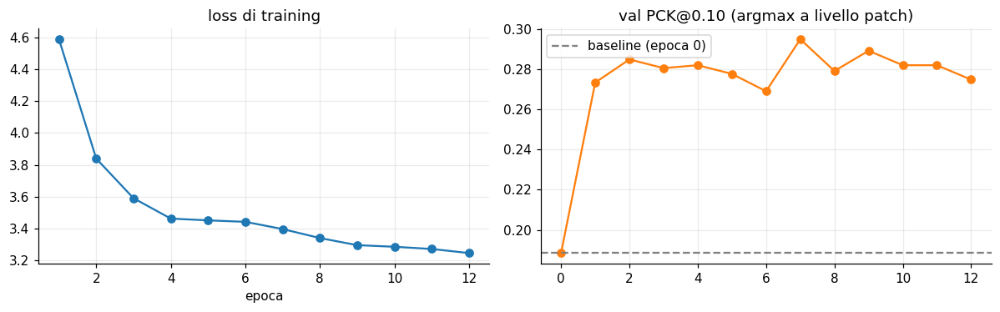

J · adapter (soft):   0%|          | 0/102 [00:00<?, ?it/s]

J · adapter + flip:   0%|          | 0/102 [00:00<?, ?it/s]

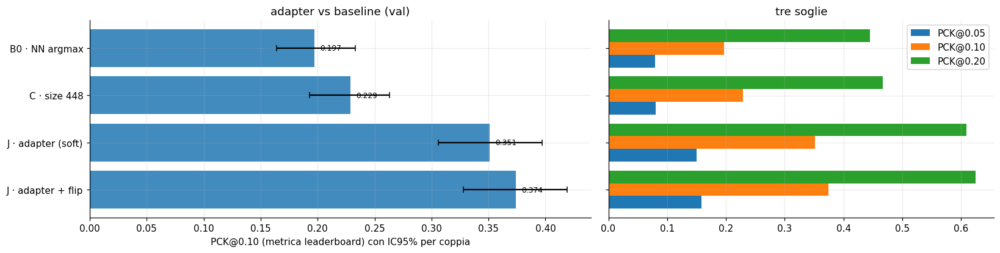

In [ ]:
ADAPTER_EPOCHS, ADAPTER_LR, ADAPTER_WD, ADAPTER_TAU = 12, 2e-3, 1e-2, 0.05
if DRY_RUN or torch is None:
    print("adapter saltato (DRY_RUN o torch assente)"); ADAPTED = None
else:
    import torch.nn as nn, torch.nn.functional as TF
    class Adapter(nn.Module):
        def __init__(s, C): super().__init__(); s.lin = nn.Linear(C, C, bias=False); nn.init.zeros_(s.lin.weight)
        def forward(s, x): return TF.normalize(x + s.lin(x), dim=-1)              # x (...,C)

    def pair_tensors(pid, ex):
        p = PAIRS_TR[pid]; Fs = torch.from_numpy(ex.feats(p["source_image"])).to(DEVICE); Ft = torch.from_numpy(ex.feats(p["target_image"])).to(DEVICE)
        sub = tr[tr.pair_id == pid]; Ws, Hs = p["source_size"]; Wt, Ht = p["target_size"]; gh, gw = Ft.shape[1:]
        u = torch.tensor([(r.source_x / Ws * Fs.shape[2] - .5) for r in sub.itertuples()], device=DEVICE); v = torch.tensor([(r.source_y / Hs * Fs.shape[1] - .5) for r in sub.itertuples()], device=DEVICE)
        ii, jj = torch.meshgrid(torch.arange(gh, device=DEVICE), torch.arange(gw, device=DEVICE), indexing="ij"); lab = []
        for r in sub.itertuples():
            sig = max(0.75, 0.05 * r.scale * gw / Wt); L = torch.zeros(gh, gw, device=DEVICE)
            for (x, y) in r.targets: L += torch.exp(-((jj - (x / Wt * gw - .5)) ** 2 + (ii - (y / Ht * gh - .5)) ** 2) / (2 * sig ** 2))
            lab.append((L / L.sum()).reshape(-1))
        return dict(Fs=Fs, Ft=Ft, u=u, v=v, lab=torch.stack(lab), sub=sub, Wt=Wt, Ht=Ht, gh=gh, gw=gw)

    def sample_src(Fs_adapted, u, v):                                              # Fs_adapted (gh,gw,C) → (n,C), bilineare
        gh, gw, C = Fs_adapted.shape; g = torch.stack([2 * u / max(gw - 1, 1) - 1, 2 * v / max(gh - 1, 1) - 1], -1)[None, None]
        out = TF.grid_sample(Fs_adapted.permute(2, 0, 1)[None], g, align_corners=True, padding_mode="border")[0, :, 0].T; return TF.normalize(out, dim=-1)

    def forward_logits(ad, T):
        Fs = ad(T["Fs"].permute(1, 2, 0)); Ft = ad(T["Ft"].permute(1, 2, 0)).reshape(-1, T["Ft"].shape[0]); return sample_src(Fs, T["u"], T["v"]) @ Ft.T   # (n, gh*gw)

    @torch.no_grad()
    def eval_pairs(ad, data):
        ok = []
        for T in data:
            lg = forward_logits(ad, T).argmax(1).cpu().numpy()
            for k, r in enumerate(T["sub"].itertuples()):
                i, j = divmod(int(lg[k]), T["gw"]); ok.append(norm_err(((j + .5) / T["gw"] * T["Wt"], (i + .5) / T["gh"] * T["Ht"]), r.targets, r.scale) <= .1)
        return float(np.mean(ok))

    ex_tr = get_main_extractor(IMG_SIZE)
    trn_pids, val_pids = list(tr[~tr.is_val].pair_id.unique()), list(tr[tr.is_val].pair_id.unique())
    data_trn = [pair_tensors(p, ex_tr) for p in tqdm(trn_pids, desc="tensori train")]; data_val = [pair_tensors(p, ex_tr) for p in val_pids]
    C = data_trn[0]["Fs"].shape[0]; ad = Adapter(C).to(DEVICE); opt = torch.optim.AdamW(ad.parameters(), lr=ADAPTER_LR, weight_decay=ADAPTER_WD)
    hist = dict(loss=[], val_pck=[eval_pairs(ad, data_val)], ep=[0]); best = (hist["val_pck"][0], {k: v.clone() for k, v in ad.state_dict().items()}, 0)
    print(f"epoca 0 (= baseline) val PCK@0.10: {hist['val_pck'][0]:.3f}")
    for ep in range(1, ADAPTER_EPOCHS + 1):
        ad.train(); order = np.random.permutation(len(data_trn)); tot = 0
        for b in range(0, len(order), 8):
            opt.zero_grad(); loss = 0
            for k in order[b:b + 8]:
                T = data_trn[k]; lg = forward_logits(ad, T) / ADAPTER_TAU; loss = loss - (T["lab"] * TF.log_softmax(lg, -1)).sum(1).mean()
            (loss / 8).backward(); opt.step(); tot += float(loss)
        ad.eval(); v = eval_pairs(ad, data_val); hist["loss"].append(tot / len(order)); hist["val_pck"].append(v); hist["ep"].append(ep)
        if v > best[0]: best = (v, {k: x.clone() for k, x in ad.state_dict().items()}, ep)
        print(f"epoca {ep:2d}  loss {hist['loss'][-1]:.3f}  val PCK@0.10 (argmax patch) {v:.3f}")
    ad.load_state_dict(best[1]); ad.eval(); torch.save(ad.state_dict(), f"{WORK_DIR}/adapter.pt"); print("migliore epoca:", best[2], f"val PCK {best[0]:.3f}")
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5)); ax[0].plot(hist["ep"][1:], hist["loss"], "o-"); ax[0].set_title("loss di training"); ax[0].set_xlabel("epoca")
    ax[1].plot(hist["ep"], hist["val_pck"], "o-", c="C1"); ax[1].axhline(hist["val_pck"][0], ls="--", c="gray", label="baseline (epoca 0)"); ax[1].set_title("val PCK@0.10 (argmax a livello patch)"); ax[1].legend(); plt.tight_layout(); plt.show()

    class AdaptedExtractor(Extractor):
        # stessa interfaccia di Extractor, ma applica l'adapter alle feature base
        def __init__(s, base, adapter): s.__dict__.update(base.__dict__); s.base, s.adapter = base, adapter; s.name = base.name + "+adapter"
        def feats(s, path, flip=False):
            f = torch.from_numpy(s.base.feats(path, flip)).to(DEVICE).permute(1, 2, 0)
            with torch.no_grad(): return s.adapter(f).permute(2, 0, 1).cpu().numpy()
    ADAPTED = AdaptedExtractor(ex_tr, ad)
    run("J · adapter (soft)", dict(extractors=[ADAPTED], decode="soft", **SOFT), df=tr[tr.is_val])
    run("J · adapter + flip", dict(extractors=[ADAPTED], decode="soft", flip=True, **SOFT), df=tr[tr.is_val])
    plot_summary(["B0 · NN argmax", "C · size 448", "J · adapter (soft)", "J · adapter + flip"], title="adapter vs baseline (val)")

In [ ]:
if ADAPTED is not None:
    run("J · ensemble + adapter + geom", dict(extractors=[ADAPTED, get_main_extractor(672)], decode="soft", flip=True, geom=GEOM, **SOFT), df=tr[tr.is_val])

J · ensemble + adapter + geom:   0%|          | 0/102 [00:00<?, ?it/s]

## 8. Confronto finale

,n,PCK@0.05,PCK@0.10,PCK@0.20,CI95_10,err_mean,err_median
method,,,,,,,
J · adapter + flip,695,0.158,0.374,0.624,"[0.328,0.419]",0.244,0.139
J · adapter (soft),695,0.150,0.351,0.609,"[0.306,0.397]",0.259,0.151
J · ensemble + adapter + geom,695,0.163,0.331,0.586,"[0.288,0.374]",0.278,0.156
C · size 896,695,0.140,0.296,0.525,"[0.252,0.338]",0.339,0.185
D · layer ultimi 4,695,0.117,0.278,0.518,"[0.236,0.321]",0.316,0.190
C · size 672,695,0.127,0.262,0.501,"[0.225,0.300]",0.350,0.199
D · layer ultimi 2,695,0.095,0.252,0.512,"[0.215,0.288]",0.314,0.195
G · ensemble + flip,695,0.102,0.240,0.508,"[0.205,0.275]",0.345,0.196
I · geom λ=0.25 K=5,695,0.099,0.240,0.499,"[0.204,0.273]",0.328,0.200


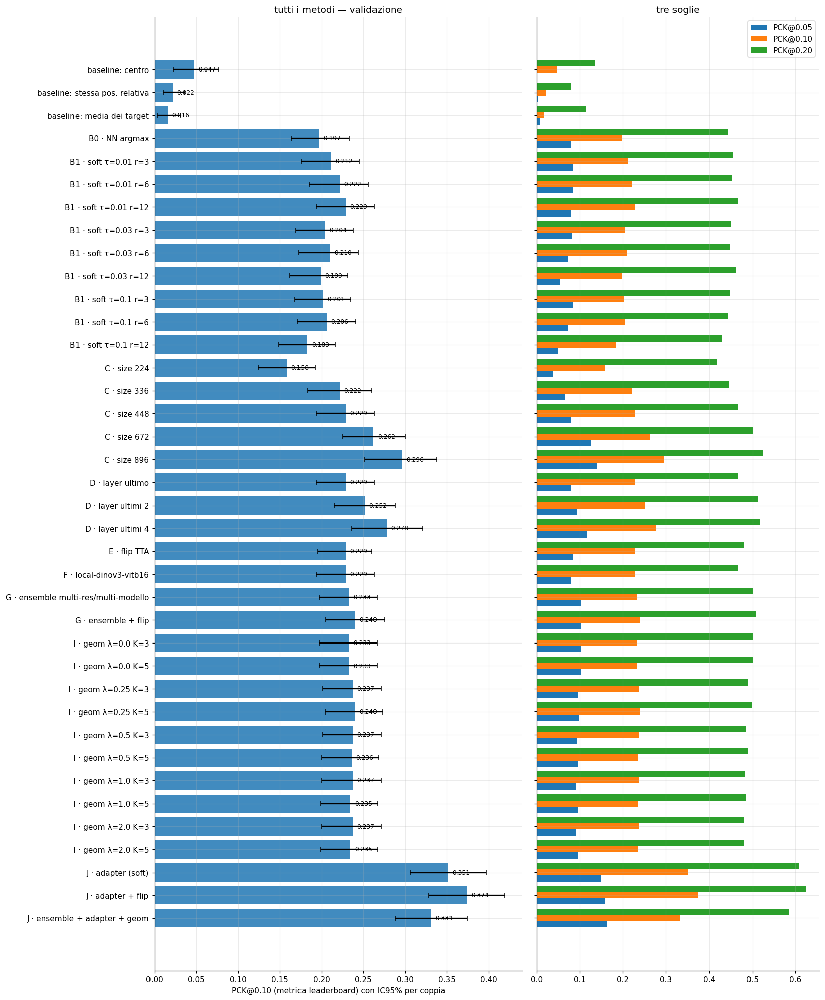


Metodi training-free anche su TUTTO il train (n≈2495):


,n,PCK@0.05,PCK@0.10,PCK@0.20,CI95_10,err_mean,err_median
method,,,,,,,
D · layer ultimi 4,2495,0.134,0.307,0.556,"[0.285,0.331]",0.329,0.174
C · size 896,2495,0.123,0.297,0.534,"[0.272,0.324]",0.394,0.181
D · layer ultimi 2,2495,0.109,0.281,0.545,"[0.259,0.305]",0.341,0.177
C · size 672,2495,0.113,0.271,0.512,"[0.250,0.292]",0.401,0.190
G · ensemble + flip,2495,0.107,0.253,0.515,"[0.232,0.277]",0.394,0.191
B1 · soft τ=0.01 r=3,2495,0.106,0.249,0.498,"[0.227,0.273]",0.395,0.201
G · ensemble multi-res/multi-modello,2495,0.108,0.245,0.513,"[0.225,0.268]",0.392,0.193
I · geom λ=0.0 K=5,2495,0.108,0.245,0.513,"[0.225,0.268]",0.392,0.193
I · geom λ=0.0 K=3,2495,0.108,0.245,0.513,"[0.225,0.268]",0.392,0.193


miglior metodo (val): J · adapter + flip


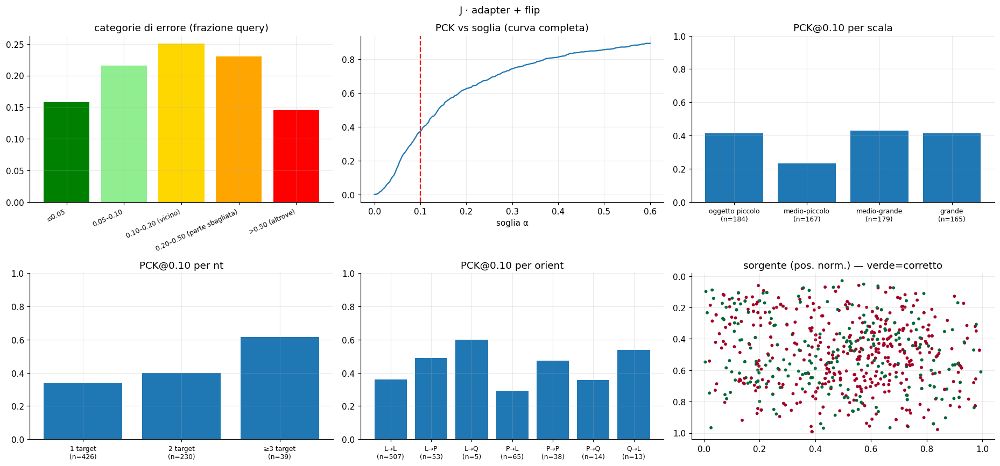

In [ ]:
T = summarize(subset="val"); display(T.sort_values("PCK@0.10", ascending=False).style.format(precision=3).background_gradient(subset=["PCK@0.10"], cmap="Greens"))
plot_summary(title="tutti i metodi — validazione")
print("\nMetodi training-free anche su TUTTO il train (n≈2495):")
Tall = summarize([k for k in RESULTS if not k.startswith("J ·")], subset="all"); display(Tall.sort_values("PCK@0.10", ascending=False).head(10).style.format(precision=3))
BEST = best_name(); print("miglior metodo (val):", BEST); diagnostics(BEST)

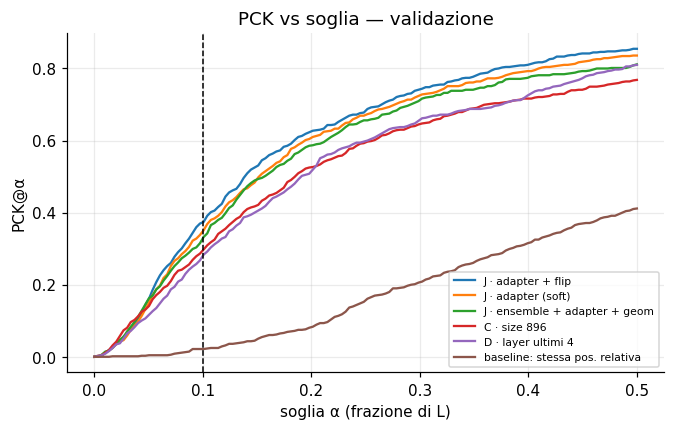

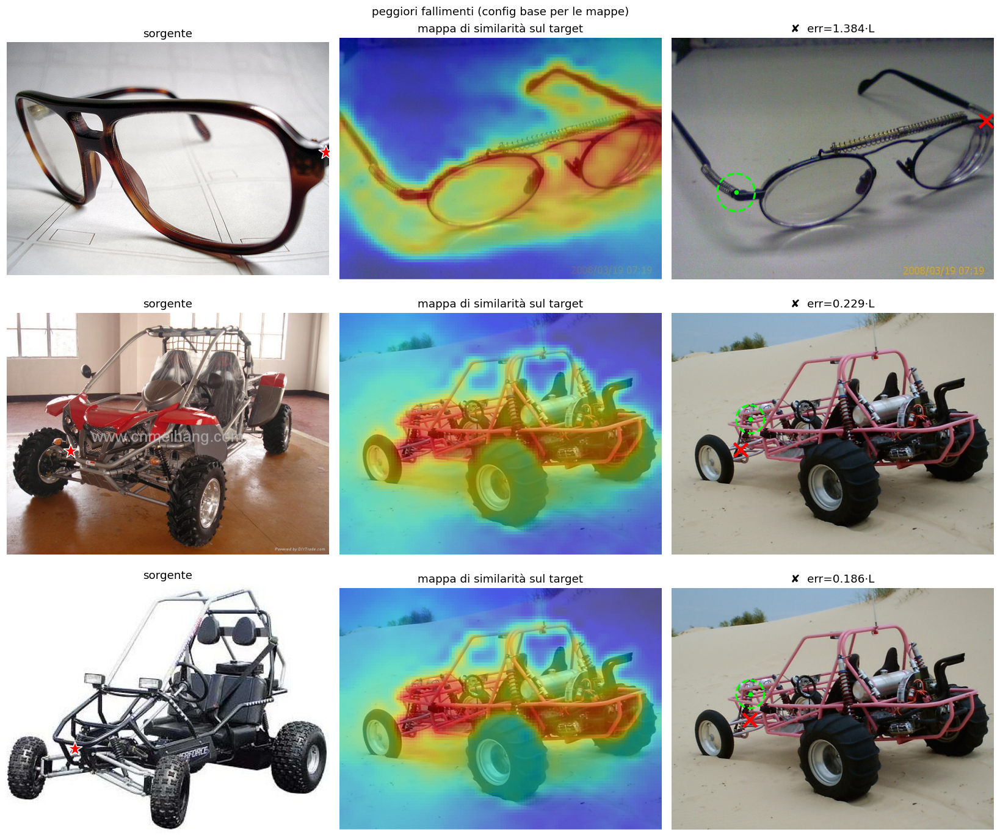

In [ ]:
# curve PCK vs soglia per i migliori metodi
top = summarize(subset="val").sort_values("PCK@0.10", ascending=False).index[:5].tolist() + ["baseline: stessa pos. relativa"]
fig, ax = plt.subplots(figsize=(7, 4)); xs = np.linspace(0, .5, 150)
for n in dict.fromkeys(top):
    e = RESULTS[n]["err"][tr.is_val].dropna(); ax.plot(xs, [(e <= x).mean() for x in xs], label=n)
ax.axvline(.1, c="k", ls="--", lw=1); ax.set_xlabel("soglia α (frazione di L)"); ax.set_ylabel("PCK@α"); ax.legend(fontsize=7); ax.set_title("PCK vs soglia — validazione"); plt.show()
# galleria dei peggiori fallimenti del miglior metodo
e = RESULTS[BEST]["err"][tr.is_val].dropna().sort_values(ascending=False)
worst = [i for i in e.index if e[i] < 5][:4]
cfg_best = dict(extractors=[EXT], decode="soft", **SOFT)  # per la visualizzazione si usa la config base; vedi sotto per quella esatta
show_maps(worst[:3], cfg_best, "peggiori fallimenti (config base per le mappe)")

## 9. Predizione sul test e submission
Scegli `FINAL_CFG` (di solito la migliore del §8). Le predizioni sono in **pixel originali del target**; vengono clippate nell'immagine. Il test non ha `scale`: non è necessario per predire.

In [ ]:
# ---- scegli qui la configurazione finale ----
FINAL_CFG = dict(extractors=ens_ex, decode="soft", flip=True, geom=GEOM, **SOFT)       # esempio: ensemble + flip + geometria
if "ADAPTED" in globals() and ADAPTED is not None and False:                           # → metti True per usare l'adapter
    FINAL_CFG = dict(extractors=[ADAPTED, get_main_extractor(672)], decode="soft", flip=True, geom=GEOM, **SOFT)

rows = []
for pid in tqdm(te.pair_id.unique(), desc="test"):
    pair = PAIRS_TE[pid]; out = predict_pair(pair, FINAL_CFG); Wt, Ht = pair["target_size"]
    for r in te[te.pair_id == pid].itertuples():
        x, y = out[r.query_index]; rows.append((r.id, float(np.clip(x, 0, Wt - 1)), float(np.clip(y, 0, Ht - 1))))
pred = pd.DataFrame(rows, columns=["id", "x", "y"]); pred.to_csv(f"{WORK_DIR}/predictions.csv", index=False)

# ---- stesso formato di make_submission.py ----
def make_submission(pred, test, out_path):
    assert set(pred.columns) == {"id", "x", "y"} and not pred.id.duplicated().any() and len(pred) == len(test) and set(pred.id) == set(test.id)
    xy = pred.set_index("id").loc[test.id, ["x", "y"]].to_numpy(float); assert np.isfinite(xy).all()
    pd.DataFrame({"id": test.id, "prediction": [json.dumps(v.tolist()) for v in xy]}).to_csv(out_path, index=False)
make_submission(pred, te, f"{WORK_DIR}/submission.csv")
sub = pd.read_csv(f"{WORK_DIR}/submission.csv"); print(sub.head(3)); print("righe:", len(sub), "| formato prediction ok:", all(isinstance(json.loads(p), list) and len(json.loads(p)) == 2 for p in sub.prediction))
sample_p = f"{DATA_DIR}/sample_submission.csv"
if os.path.exists(sample_p): print("ID identici al sample_submission:", set(pd.read_csv(sample_p).id) == set(sub.id))
# (equivalente da shell: python make_submission.py --test test.csv --predictions work/predictions.csv --output work/submission.csv)

test:   0%|          | 0/98 [00:00<?, ?it/s]

             id                               prediction
0  test_q_00341    [175.5002222200807, 56.1301719136272]
1  test_q_00212   [232.9878674888431, 127.1118245413998]
2  test_q_00426  [140.14580111144073, 374.4782008888486]
righe: 577 | formato prediction ok: True
ID identici al sample_submission: True


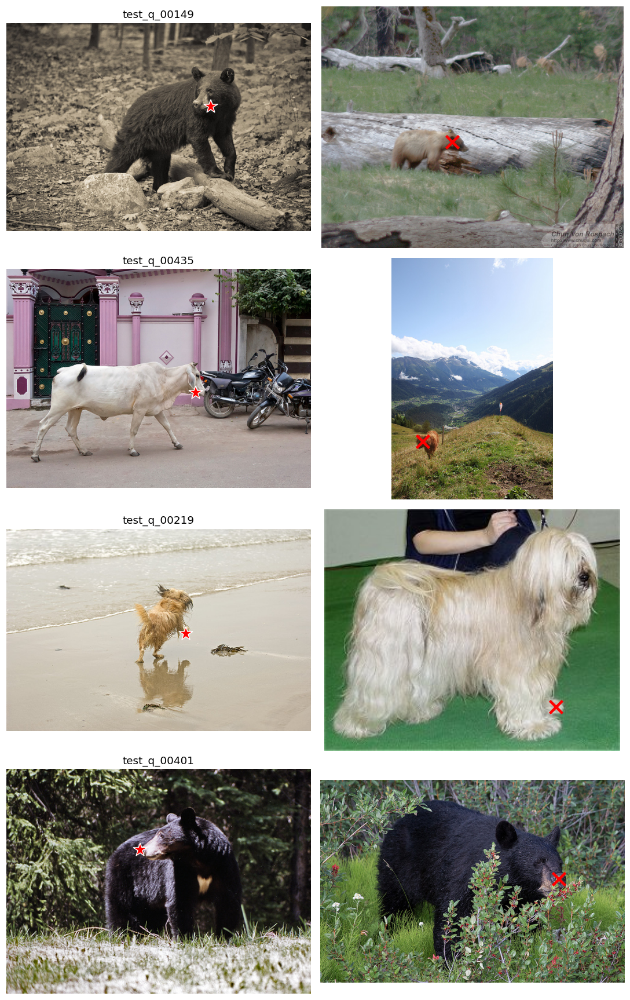

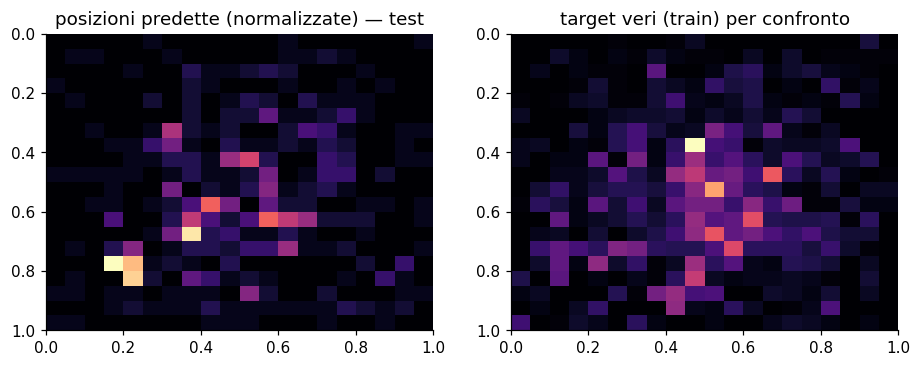

In [ ]:
# controllo visivo sul test: la predizione cade su una parte plausibile?
idx = list(te.sample(4, random_state=0).index); pr = pred.set_index("id"); fig, axs = plt.subplots(4, 2, figsize=(10, 16))
for k, i in enumerate(idx):
    r = te.loc[i]; si, ti = EXT._open(r.source_image), EXT._open(r.target_image)
    axs[k, 0].imshow(si); axs[k, 0].plot(r.source_x, r.source_y, "r*", ms=16, mec="w"); axs[k, 1].imshow(ti); axs[k, 1].plot(pr.loc[r.id, "x"], pr.loc[r.id, "y"], "rx", ms=14, mew=3)
    axs[k, 0].set_title(r.id); [a.axis("off") for a in axs[k]]
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5)); t2 = te.merge(pred, on="id")
ax[0].hist2d(t2.x / t2.tw, t2.y / t2.th, bins=20, range=[[0, 1], [0, 1]], cmap="magma"); ax[0].invert_yaxis(); ax[0].set_title("posizioni predette (normalizzate) — test"); ax[0].grid(False)
ax[1].hist2d(tx, ty, bins=20, range=[[0, 1], [0, 1]], cmap="magma"); ax[1].invert_yaxis(); ax[1].set_title("target veri (train) per confronto"); ax[1].grid(False); plt.show()

## 10. Prossimi passi
* **Leaderboard ≠ validazione**: la validazione qui ha ~600 query (IC ±2–3 punti). Sottometti poche varianti, scegli quelle con vantaggio chiaro su val.
* **Più forti**: adapter non lineare / LoRA sul backbone; fine-tuning con loss sul PCK (come in Qian et al.: forme allineate + supervisione semantica); mappe di diversi backbone (DINOv3-L, SD features) in ensemble; crop sull'oggetto target (rilevato dalla mappa di similarità aggregata) per risoluzione efficace maggiore sugli oggetti piccoli.
* **Più furbi**: sfrutta tutti i punti sorgente della coppia con una trasformazione non rigida (TPS) invece dell'affine; per query con più target accettati valuta il picco che massimizza la copertura dei candidati.
* **Controllo regolamento**: verifica che i modelli pre-addestrati usati e i dati esterni siano consentiti prima di sottomettere.